# LIFE-seq Figure 5 and Supplementary Figures S8c, S9 and S10

English: Transcriptomic analyses of ten longitudinal LIFE-seq captures: sample relationships, dynamic gene modules, spatial clusters and differential expression. The UMAP views are shown together, and the spatial overview includes all ten captures. See [README](README.md) for inputs, requirements and manuscript-panel mapping.

中文：展示十次LIFE-seq采样的转录组关系、动态基因模块、空间聚类及差异表达。三种着色的UMAP并排展示，十样本空间图合为一张总览。输入、依赖和图版对应见README。


[Repository overview](../README.md) · [Figure guide](README.md)

中文：运行范围、输入布局和数据说明见上述文档。

## Setup and input data / 环境与输入

English: Run the cells in order using a Python kernel. Input locations are configured below; figures are displayed inline.

中文：使用Python内核从上到下运行。下方配置输入路径，图片直接显示在对应cell下。


In [1]:
# 中文：导入依赖、设置相对路径和固定配色。
# English: Import dependencies; configure relative paths and fixed palettes.
from pathlib import Path
import os, io, hashlib, re, textwrap
import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, FancyArrowPatch, Rectangle
from matplotlib.colors import LinearSegmentedColormap, Normalize, PowerNorm
from matplotlib.ticker import MaxNLocator
from scipy import sparse, stats
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import gaussian_filter1d, gaussian_filter, map_coordinates
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Image

DATA = Path('data')
INPUT_H5AD = Path(os.environ.get('LIFESEQ_INPUT_H5AD', '../../merged_10_LIFEseq.h5ad'))
assert DATA.is_dir(), 'Open this notebook from its own directory.'
assert INPUT_H5AD.is_file(), 'Set INPUT_H5AD to the relative location of merged_10_LIFEseq.h5ad.'
SAMPLES = ['WJD0-1', 'WJD0-2', 'WJD1-1', 'WJD1-2', 'WJD2-1',
           'WJD2-2', 'WJD2-3', 'WJD3-1', 'WJD3-2', 'WJD3-3']
TIMEPOINTS = ['D0', 'D1', 'D2', 'D3']
SAMPLE_TIME = {s: s[2:4] for s in SAMPLES}
CLUSTERS = [f'Cluster {i}' for i in range(1, 7)]
MODULES = [f'Module {i}' for i in range(1, 6)]
EXPECTED_SIZES = [212, 57, 745, 1814, 511]
TIME_COLORS = dict(zip(TIMEPOINTS, ['#AFC7E8', '#A9D5C3', '#E8D3A9', '#E6B0AA']))
MODULE_COLORS = ['#3B82B6', '#57A477', '#D7A24B', '#B06BA0', '#D26A5A']
CLUSTER_COLORS = dict(zip(CLUSTERS, sc.pl.palettes.default_20))
MUTED_PALETTE = ['#7E9BB1', '#C5A78C', '#91A995', '#BE9696', '#AA9BB8',
                 '#AA9B8E', '#B8A7AD', '#AFB28E', '#7FA7A5', '#A8BCC9']
SAMPLE_COLORS = dict(zip(SAMPLES, MUTED_PALETTE))
INLINE_DPI = 180
FIGURE_OUTPUTS = []
def set_style(size=10):
    mpl.rcdefaults()
    mpl.rcParams.update({'font.family': 'Arial', 'font.size': size,
        'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
        'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.linewidth': .8})
def save_figure(fig, name, tight=True):
    # 中文：仅在内存中渲染，并将图片嵌入当前 cell。
    # English: Render in memory and embed the image in this cell only.
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=INLINE_DPI, facecolor='white',
                **({'bbox_inches': 'tight'} if tight else {}))
    display(Image(data=buffer.getvalue(), width=min(1200, int(fig.get_figwidth()*110))))
    FIGURE_OUTPUTS.append(name)
    plt.close(fig)
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()
set_style()


In [2]:
# 中文：载入计数矩阵并对齐spot、样本与聚类标签。
# English: Load the count matrix and align spot, sample and cluster identifiers.
INPUT_HASH = sha256(INPUT_H5AD)
assert INPUT_HASH == '67f4eebaefbec323716fdb1be15184e10d548cc4c366391960f9df953acc99e9', 'Input checksum mismatch: supply the published merged_10_LIFEseq.h5ad count matrix.'
backed = ad.read_h5ad(INPUT_H5AD, backed='r')
try:
    raw = backed.to_memory()
finally:
    backed.file.close()
assert raw.shape == (10270, 38618) and raw.obs_names.is_unique and raw.var_names.is_unique
assert sparse.issparse(raw.X) and np.isfinite(raw.X.data).all() and (raw.X.data >= 0).all()
umap_table = pd.read_csv(DATA / 'umap_coordinates.csv')
assert umap_table.obs_name.is_unique and set(umap_table.obs_name) == set(raw.obs_names)
umap_table = umap_table.set_index('obs_name').loc[raw.obs_names].reset_index(names='obs_name')
for field in ['sample_name', 'source_obs_name']:
    np.testing.assert_array_equal(umap_table[field].astype(str), raw.obs[field].astype(str))
np.testing.assert_array_equal(umap_table.timepoint, raw.obs.timepoint.astype(str).str.replace('Day', 'D', regex=False))
sample_labels = raw.obs.sample_name.astype(str).to_numpy()
cluster_labels = umap_table.cluster_r0_4.to_numpy()
umap = umap_table[['UMAP1', 'UMAP2']].to_numpy()
counts = pd.crosstab(umap_table.sample_name, umap_table.cluster_r0_4).reindex(index=SAMPLES, columns=CLUSTERS, fill_value=0)
assert counts.sum().tolist() == [2964, 2812, 1570, 1309, 1261, 354]
sample_proportions = counts.div(counts.sum(axis=1), axis=0)
sample_summary = pd.DataFrame({'sample': SAMPLES, 'timepoint': [SAMPLE_TIME[s] for s in SAMPLES], 'n_spots': counts.sum(axis=1).to_numpy()})
display(sample_summary)


,sample,timepoint,n_spots
0,WJD0-1,D0,1528
1,WJD0-2,D0,1425
2,WJD1-1,D1,747
3,WJD1-2,D1,1089
4,WJD2-1,D2,1736
5,WJD2-2,D2,1240
6,WJD2-3,D2,990
7,WJD3-1,D3,470
8,WJD3-2,D3,518
9,WJD3-3,D3,527


## Figure 5b — Sample-level PCA / 样本级PCA

English: Counts are aggregated by sample. Genes must be detected in at least three spots and have CPM ≥ 1 in at least two samples; mt-/Rpl/Rps genes are excluded. PCA uses the 3,000 most variable genes, with centering and no variance scaling. Ellipses and arrows are visual guides.

中文：按样本汇总计数，筛选至少3个spot检出且至少2个样本CPM≥1的基因，排除mt-/Rpl/Rps，取方差最高的3000基因进行中心化PCA。椭圆和箭头为视觉辅助。


In [3]:
# 中文：计算样本PCA并统一主成分符号。
# English: Calculate sample-level PCA and orient principal-component signs.
gene_keep = np.asarray((raw.X > 0).sum(axis=0)).ravel() >= 3
assert int(gene_keep.sum()) == 32137
filtered_counts = raw.X[:, gene_keep].tocsr()
pseudobulk = pd.DataFrame(np.vstack([np.asarray(filtered_counts[sample_labels == s].sum(axis=0)).ravel() for s in SAMPLES]), index=SAMPLES, columns=raw.var_names[gene_keep])
cpm = pseudobulk.div(pseudobulk.sum(axis=1), axis=0) * 1e6
logcpm = np.log2(cpm.loc[:, cpm.ge(1).sum(axis=0).ge(2)] + 1)
names = logcpm.columns.astype(str)
logcpm = logcpm.loc[:, ~(names.str.lower().str.startswith('mt-') | names.str.startswith(('Rpl', 'Rps')))]
rank = np.argsort(-logcpm.var(axis=0, ddof=0).to_numpy(), kind='mergesort')[:3000]
pca_model = PCA(n_components=7, random_state=0, svd_solver='auto')
xy = pca_model.fit_transform(logcpm.iloc[:, rank].to_numpy())[:, :2]
pca_reference = pd.read_csv(DATA / 'pca_reference.csv', float_precision='round_trip').set_index('sample_name').loc[SAMPLES]
for j, pc in enumerate(['PC1', 'PC2']):
    if np.dot(xy[:, j], pca_reference[pc].to_numpy()) < 0:
        xy[:, j] *= -1
np.testing.assert_allclose(xy, pca_reference[['PC1', 'PC2']], rtol=2e-5, atol=2e-4)
variance = pd.Series(pca_model.explained_variance_ratio_[:2] * 100)
np.testing.assert_allclose(variance, pca_reference[['PC1_variance', 'PC2_variance']].iloc[0], rtol=1e-5)
pca_table = pca_reference.copy()
pca_table[['PC1', 'PC2']] = xy
print('PCA variance / 方差解释率 (%):', np.round(variance.to_numpy(), 4))


PCA variance / 方差解释率 (%): [48.352  22.0646]


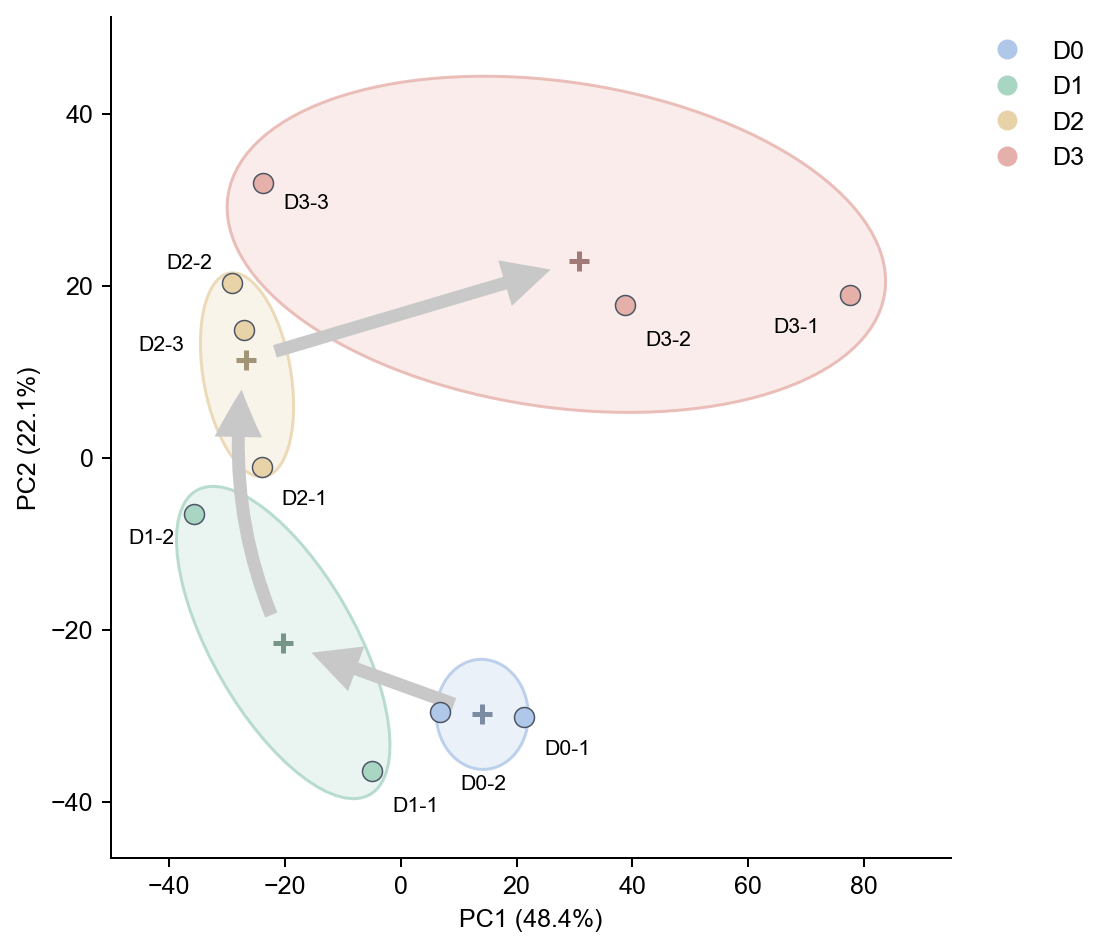

In [4]:
# 中文：图5b：绘制样本PCA。
# English: Figure 5b: plot sample-level PCA.
set_style()
pca_df = pca_table[["PC1", "PC2"]]
centers = pca_table.groupby("timepoint")[["PC1", "PC2"]].mean().reindex(TIMEPOINTS)
span = np.ptp(pca_df.to_numpy(), axis=0)
# 椭圆为绘图辅助，参数控制轴长与角度，不表示置信区间。
ellipse_style = {
    "D0": (15.92868448575336, 12.8, 177.62035905959806),
    "D1": (47.124847266410114, 21.420385121095507, 135.63961506412713),
    "D2": (24.557074940357847, 14.8, 108.82809134822949),
    "D3": (114.10029716693842, 38.03343238897947, 175.14390934500935),
}
fig, ax = plt.subplots(figsize=(7.0, 5.4))
theta = np.linspace(0, 2 * np.pi, 361)
boundaries = []
for t in TIMEPOINTS:
    group = pca_table.loc[pca_table.timepoint.eq(t), ["PC1", "PC2"]].to_numpy()
    center = centers.loc[t].to_numpy() if t in ["D0", "D1"] else (group.min(axis=0) + group.max(axis=0)) / 2
    width, height, degree = ellipse_style[t]
    ax.add_patch(Ellipse(center, width=width, height=height, angle=degree,
                        facecolor=mpl.colors.to_rgba(TIME_COLORS[t], .24),
                        edgecolor=mpl.colors.to_rgba(TIME_COLORS[t], .8), linewidth=1.2, zorder=1))
    angle = np.deg2rad(degree)
    rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    boundaries.append(np.column_stack([width / 2 * np.cos(theta), height / 2 * np.sin(theta)]) @ rotation.T + center)

for earlier, later in zip(TIMEPOINTS, TIMEPOINTS[1:]):
    ax.add_patch(FancyArrowPatch(centers.loc[earlier].to_numpy(), centers.loc[later].to_numpy(),
        arrowstyle="Simple,tail_width=5.2,head_width=19,head_length=19", mutation_scale=1,
        facecolor="#C8C8C8", edgecolor="none", linewidth=0, shrinkA=12, shrinkB=12,
        connectionstyle="arc3,rad=-0.16" if earlier=="D1" else "arc3,rad=0", zorder=2))

offsets = {"WJD0-1": (8,-9), "WJD0-2": (8,-25), "WJD1-1": (8,-10), "WJD1-2": (-8,-6),
           "WJD2-1": (8,-9), "WJD2-2": (-8,4), "WJD2-3": (-24,-2),
           "WJD3-1": (-12,-9), "WJD3-2": (8,-10), "WJD3-3": (8,-4)}
for s in SAMPLES:
    x, y = pca_df.loc[s]; dx, dy = offsets[s]
    ax.scatter(x,y,s=64,c=TIME_COLORS[SAMPLE_TIME[s]],edgecolor="#4B5563",linewidth=.6,zorder=4)
    ax.annotate(s.replace("WJ",""),(x,y),xytext=(dx,dy),textcoords="offset points",fontsize=8.5,
                ha="left" if dx>0 else "right",va="bottom" if dy>0 else "top",zorder=6)
for t in TIMEPOINTS:
    ax.scatter(*centers.loc[t],s=58,marker="+",
               color=np.array(mpl.colors.to_rgb(TIME_COLORS[t]))*.70,linewidth=2,zorder=5)
extent = np.vstack(boundaries)
ax.set_xlim(extent[:,0].min()-span[0]*.10,extent[:,0].max()+span[0]*.10)
ax.set_ylim(extent[:,1].min()-span[1]*.10,extent[:,1].max()+span[1]*.10)
ax.set(xlabel=f"PC1 ({variance.iloc[0]:.1f}%)",ylabel=f"PC2 ({variance.iloc[1]:.1f}%)")
ax.set_box_aspect(1)
ax.legend(handles=[Line2D([0],[0],marker="o",linestyle="none",color=TIME_COLORS[t],label=t,markersize=7)
                   for t in TIMEPOINTS],frameon=False,loc="upper left",bbox_to_anchor=(1.01,1))
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout()
save_figure(fig, "Fig5b_PCA")


## Figure 5c–d — Dynamic gene modules / 动态基因模块

English: Per-spot normalization to 10,000 counts and log1p transformation precede sample averaging. Sample-level ANOVA with BH correction identifies 3,339 dynamic genes among 12,728 eligible genes. The five module assignments and heatmap row order are provided in data/. Trajectory shading represents the inter-gene interquartile range.

中文：每spot归一化至10,000计数并log1p，样本内含零取均值。样本级ANOVA/BH从12,728个合格基因中得到3,339个动态基因。五模块成员和热图行序见data；轨迹阴影为基因间四分位范围。


In [5]:
# 中文：计算样本平均表达并筛选动态基因。
# English: Calculate sample mean expression and identify dynamic genes.
normalized = raw.copy()
sc.pp.normalize_total(normalized, target_sum=10000)
sc.pp.log1p(normalized)
sample_codes = pd.Categorical(sample_labels, categories=SAMPLES).codes
sample_sizes = np.bincount(sample_codes, minlength=10)
weights = sparse.csr_matrix((1 / sample_sizes[sample_codes], (sample_codes, np.arange(raw.n_obs))), shape=(10, raw.n_obs))
sample_values = np.asarray((weights @ normalized.X).toarray()).T
sample_expression = pd.DataFrame(sample_values, index=raw.var_names, columns=SAMPLES)
time_means_all = pd.DataFrame({t: sample_expression[[s for s in SAMPLES if SAMPLE_TIME[s] == t]].mean(axis=1) for t in TIMEPOINTS})
eligible = (sample_values >= .05).sum(axis=1) >= 2
assert int(eligible.sum()) == 12728
tested = sample_expression.loc[eligible]
groups = [tested[[s for s in SAMPLES if SAMPLE_TIME[s] == t]].to_numpy().T for t in TIMEPOINTS]
within_ss = sum(((g - g.mean(axis=0)) ** 2).sum(axis=0) for g in groups)
testable = (np.ptp(tested.to_numpy(), axis=1) > 0) & (within_ss > 0)
pvalues = np.ones(len(tested))
pvalues[testable] = stats.f_oneway(*(g[:, testable] for g in groups), axis=0).pvalue
fdr = multipletests(pvalues, method='fdr_bh')[1]
module_table = pd.read_csv(DATA / 'dynamic_module_genes.csv', float_precision='round_trip').sort_values('heatmap_order')
assert set(tested.index[fdr < .05]) == set(module_table.gene)
assert module_table.groupby('module').size().reindex(MODULES).tolist() == EXPECTED_SIZES
module_expression = sample_expression.loc[module_table.gene, SAMPLES]
time_values = time_means_all.loc[module_table.gene, TIMEPOINTS].to_numpy()
np.testing.assert_allclose(time_values, module_table[[f'{t}_mean' for t in TIMEPOINTS]], rtol=1e-6, atol=1e-7)
centering = time_values.mean(axis=1)
scaling = time_values.std(axis=1, ddof=0)
z_time = (time_values - centering[:, None]) / scaling[:, None]
z_sample = (module_expression.to_numpy() - centering[:, None]) / scaling[:, None]
np.testing.assert_allclose(z_time, module_table[[f'row_z_{t}' for t in TIMEPOINTS]], rtol=1e-6, atol=1e-6)
print('ANOVA/BH:', len(tested), 'tested;', len(module_table), 'dynamic genes; modules:', EXPECTED_SIZES)


ANOVA/BH: 12728 tested; 3339 dynamic genes; modules: [212, 57, 745, 1814, 511]


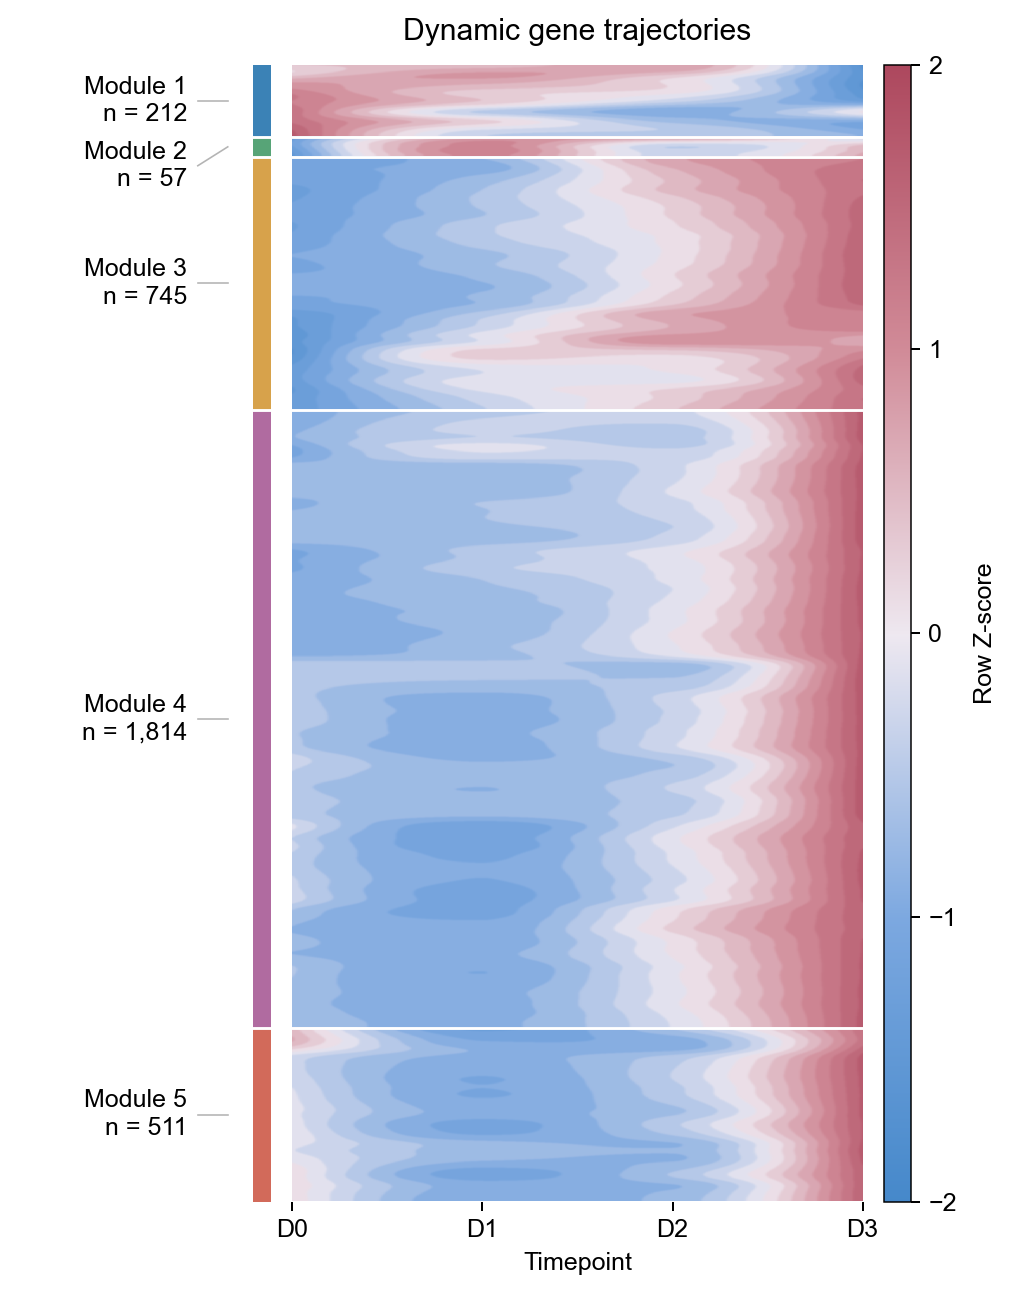

In [6]:
# 中文：图5c：插值和模块内柔化仅用于显示，不参与统计。
# English: Figure 5c: interpolation and within-module smoothing affect display only.
set_style()
# 中文：热图仅在每个模块内部平滑显示颜色。
# English: Smooth heatmap display colors within each module independently.
module_table = pd.read_csv(DATA / "dynamic_module_genes.csv", float_precision="round_trip").sort_values("heatmap_order")
row_z = module_table[[f"row_z_{t}" for t in TIMEPOINTS]].to_numpy()
module_sizes = module_table.groupby("module", sort=False).size().to_dict()
N_DYNAMIC = len(module_table)
time_grid=np.linspace(0,3,901)
heatmap_values=PchipInterpolator(np.arange(4),row_z,axis=1,extrapolate=False)(time_grid)
module_ends=np.cumsum(list(module_sizes.values()));module_starts=np.r_[0,module_ends[:-1]]
# display_values是独立显示副本，不用于ANOVA、聚类、marker或program score。
DISPLAY_SIGMA_ROWS=12.0
display_values=heatmap_values.copy()
for m,start,end in zip(module_sizes,module_starts,module_ends):
    sigma=min(DISPLAY_SIGMA_ROWS,(end-start)/6)
    display_values[start:end]=gaussian_filter1d(heatmap_values[start:end],sigma=sigma,axis=0,mode='reflect',truncate=3)
soft_cmap=LinearSegmentedColormap.from_list('LIFEseq_soft_blue_rose',['#4588CA','#7CA8E0','#EEE8F0','#D18B98','#AD485E'],N=1024)
fig=plt.figure(figsize=(6.4,8.2));gs=fig.add_gridspec(1,4,width_ratios=[1.5,.13,4,.19],wspace=.10)
labelax=fig.add_subplot(gs[0]);barax=fig.add_subplot(gs[1]);ax=fig.add_subplot(gs[2]);cax=fig.add_subplot(gs[3])
step=time_grid[1]-time_grid[0]
# PDF密集颜色层为位图，模块条、标签、边界和色标保留矢量。
# 分级填色后轻柔化边缘，得到参考图的云状色块；颜色处理同样不跨模块。
level_step=.2
display_color_values=np.clip(np.floor((display_values+2)/level_step)*level_step-2+level_step/2,-2,2)
display_rgba=soft_cmap(mpl.colors.Normalize(-2,2)(display_color_values)).astype(np.float32)
for start,end in zip(module_starts,module_ends):
    block=display_rgba[start:end]
    block=gaussian_filter1d(block,sigma=2,axis=0,mode='reflect',truncate=3)
    display_rgba[start:end]=gaussian_filter1d(block,sigma=2,axis=1,mode='nearest',truncate=3)
ax.imshow(display_rgba,origin='upper',aspect='auto',interpolation='nearest',resample=False,extent=(-step/2,3+step/2,N_DYNAMIC,0))
im=mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(-2,2),cmap=soft_cmap)
for i,(start,end) in enumerate(zip(module_starts,module_ends)):
    barax.add_patch(Rectangle((0,start),1,end-start,facecolor=MODULE_COLORS[i],edgecolor='none'))
true_centers=(module_starts+module_ends)/2;label_y=true_centers.copy()
for i in range(1,5):label_y[i]=max(label_y[i],label_y[i-1]+190)
for i,(m,n) in enumerate(module_sizes.items()):
    labelax.text(.79,label_y[i],f'{m}\nn = {n:,}',ha='right',va='center',fontsize=10,linespacing=1.25)
    labelax.plot([.84,.98],[label_y[i],true_centers[i]],color='#B4B4B4',lw=.65)
for y in module_ends[:-1]:
    ax.axhline(y,color='white',lw=1.15);barax.axhline(y,color='white',lw=1.15)
ax.set_xticks(range(4),TIMEPOINTS);ax.set_yticks([]);ax.set_xlabel('Timepoint');ax.set_xlim(-step/2,3+step/2)
ax.set_title('Dynamic gene trajectories',pad=10)
for a in [labelax,barax]:a.set_xlim(0,1);a.set_ylim(N_DYNAMIC,0);a.axis('off')
for spine in ax.spines.values():spine.set_visible(False)
cb=fig.colorbar(im,cax=cax);cb.set_label('Row Z-score',labelpad=7);cb.set_ticks([-2,-1,0,1,2]);cb.outline.set_linewidth(.6)
cb.solids.set_rasterized(False);cb.solids.set_edgecolor('face')
save_figure(fig, "Fig5c_dynamic_gene_heatmap", tight=True)


In [7]:
# 中文：计算各模块全部基因的均值、基因IQR和十个样本分数。
# English: Compute all-gene module means, gene IQRs, and ten sample scores.
sample_rows, summary_rows = [], []
for module, n_genes in zip(MODULES, EXPECTED_SIZES):
    use = module_table.module.eq(module).to_numpy()
    module_samples = z_sample[use].mean(axis=0)
    for j, sample in enumerate(SAMPLES):
        sample_rows.append({'module': module, 'sample_name': sample, 'timepoint': SAMPLE_TIME[sample], 'module_mean_scaled_expression': module_samples[j]})
    for j, tp in enumerate(TIMEPOINTS):
        vals = z_time[use, j]
        sample_mean = module_samples[[SAMPLE_TIME[s] == tp for s in SAMPLES]].mean()
        np.testing.assert_allclose(vals.mean(), sample_mean, atol=1e-12)
        summary_rows.append({'module': module, 'timepoint': tp, 'module_mean_row_z': vals.mean(),
                            'gene_q25_row_z': np.quantile(vals, .25), 'gene_q75_row_z': np.quantile(vals, .75)})
module_samples = pd.DataFrame(sample_rows)
module_summary = pd.DataFrame(summary_rows)
print('Module scores / 模块分数:', module_samples.shape[0], 'sample rows;', module_summary.shape[0], 'timepoint rows')


Module scores / 模块分数: 50 sample rows; 20 timepoint rows


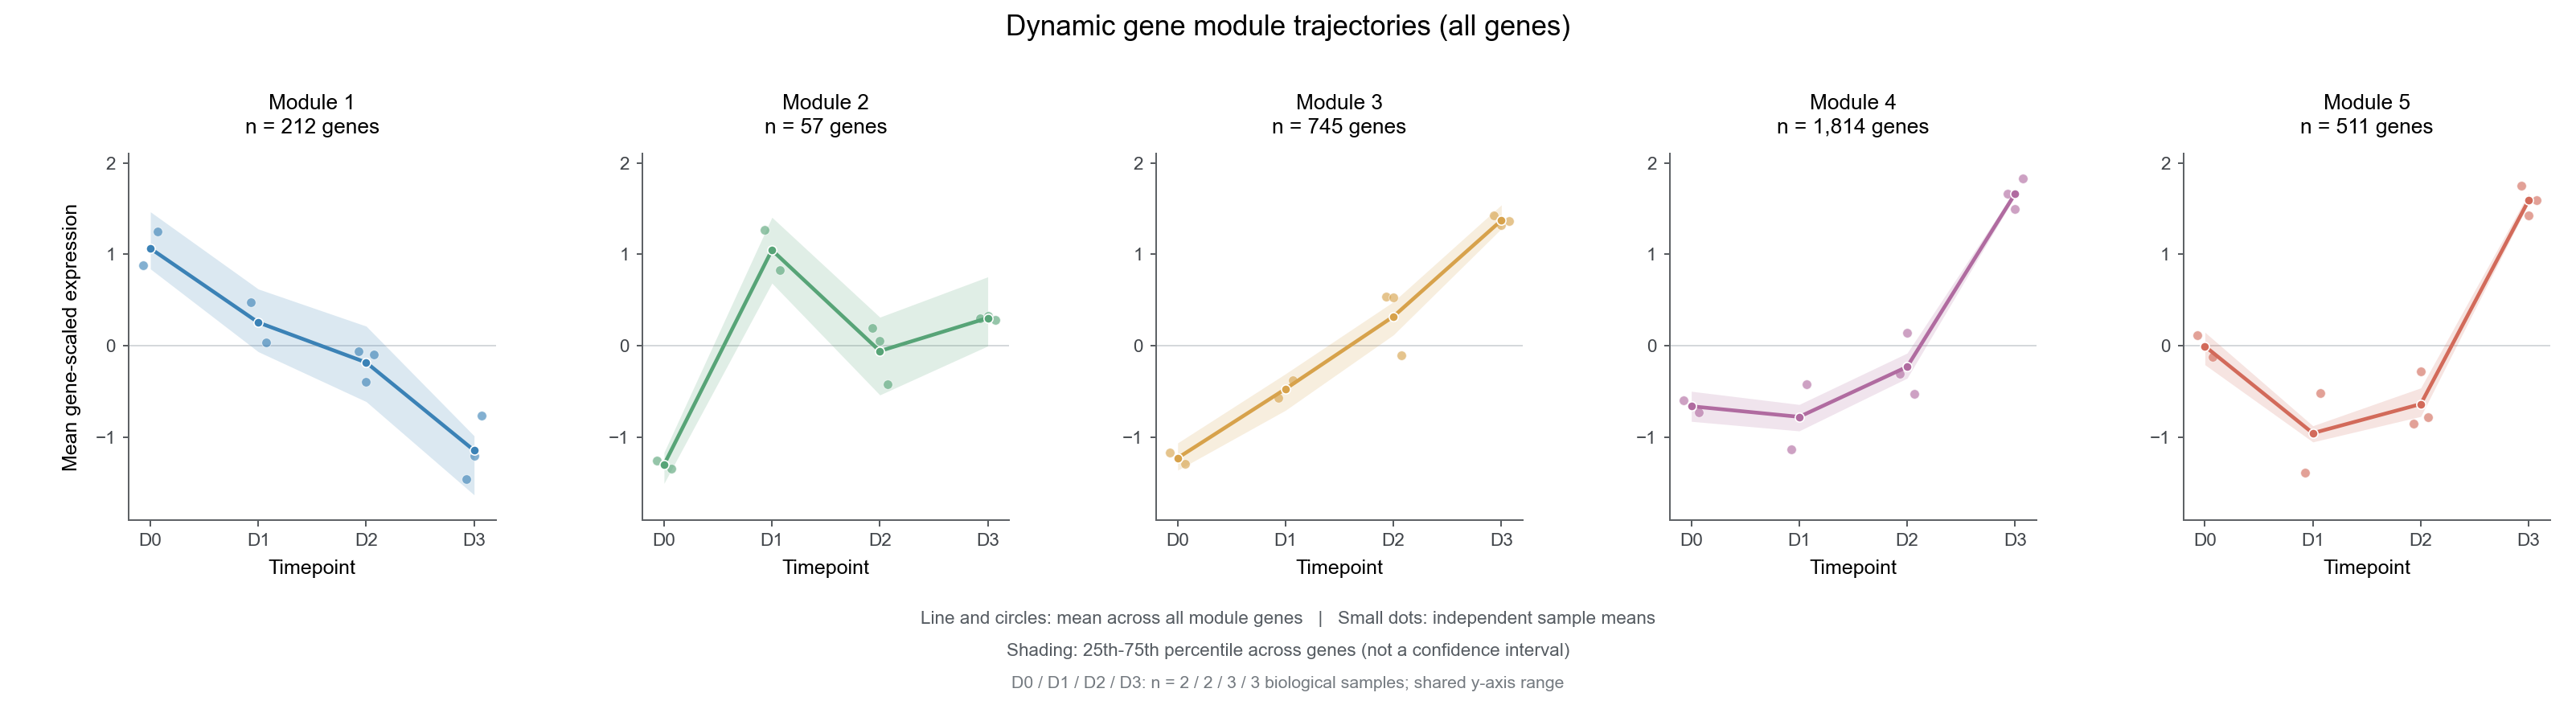

In [8]:
# 中文：图5d：阴影为基因间四分位范围，散点为各次采样均值。
# English: Figure 5d: shading is the inter-gene IQR; dots show individual capture means.
def draw_figure(samples, summary):
    mpl.rcParams.update({'font.family': 'Arial', 'font.size': 10,
                         'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
                         'figure.facecolor': 'white', 'axes.facecolor': 'white',
                         'axes.linewidth': .8})
    # Style-only inheritance: same dimensions, square panels and module colors.
    fig, axes = plt.subplots(1, 5, figsize=(17.8, 4.9), sharey=True)
    fig.subplots_adjust(left=.050, right=.990, bottom=.245, top=.805, wspace=.40)
    fig.suptitle('Dynamic gene module trajectories (all genes)', fontsize=14,
                 fontweight='medium', y=.98)
    low = min(float(summary.gene_q25_row_z.min()), float(samples.module_mean_scaled_expression.min()), 0)
    high = max(float(summary.gene_q75_row_z.max()), float(samples.module_mean_scaled_expression.max()), 0)
    pad = max((high - low) * .08, .15)
    jitter = {s: float(offset) for tp in TIMEPOINTS
              for s, offset in zip([s for s in SAMPLES if SAMPLE_TIME[s] == tp],
                                   np.linspace(-.07, .07, sum(SAMPLE_TIME[s] == tp for s in SAMPLES)))}
    for ax, module, color, n_genes in zip(axes, MODULES, MODULE_COLORS, EXPECTED_SIZES):
        ax.set_box_aspect(1)
        ax.set_xlim(-.20, 3.20)
        ax.set_ylim(low - pad, high + pad)
        ax.set_xticks(range(4), TIMEPOINTS)
        ax.set_xlabel('Timepoint', labelpad=5)
        ax.spines[['top', 'right']].set_visible(False)
        ax.spines[['left', 'bottom']].set_color('#5E6266')
        ax.tick_params(length=3, width=.7, colors='#41454A', labelsize=9, labelleft=True)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=4))
        ax.axhline(0, color='#CCD0D3', linewidth=.65, zorder=0)
        q = summary.loc[summary.module.eq(module)].set_index('timepoint').loc[TIMEPOINTS]
        pts = samples.loc[samples.module.eq(module)]
        ax.fill_between(np.arange(4), q.gene_q25_row_z.to_numpy(), q.gene_q75_row_z.to_numpy(),
                        color=color, alpha=.18, linewidth=0, zorder=1)
        ax.scatter([TIMEPOINTS.index(tp) + jitter[s] for tp, s in zip(pts.timepoint, pts.sample_name)],
                   pts.module_mean_scaled_expression, s=22, color=color, alpha=.63,
                   edgecolor='white', linewidth=.4, zorder=3)
        ax.plot(np.arange(4), q.module_mean_row_z.to_numpy(), color=color, linewidth=1.85,
                marker='o', markersize=4.5, markeredgecolor='white', markeredgewidth=.65, zorder=4)
        ax.set_title(f'{module}\nn = {n_genes:,} genes', fontsize=10.5, pad=10, linespacing=1.3)
    axes[0].set_ylabel('Mean gene-scaled expression', labelpad=7)
    fig.text(.50, .120, 'Line and circles: mean across all module genes   |   Small dots: independent sample means',
             ha='center', fontsize=9, color='#565C62')
    fig.text(.50, .075, 'Shading: 25th-75th percentile across genes (not a confidence interval)',
             ha='center', fontsize=9, color='#565C62')
    fig.text(.50, .030, 'D0 / D1 / D2 / D3: n = 2 / 2 / 3 / 3 biological samples; shared y-axis range',
             ha='center', fontsize=8.5, color='#747A80')
    save_figure(fig, 'Fig5d_module_trajectories', tight=False)

draw_figure(module_samples, module_summary)


## Figure 5e–g and S10a–b — UMAP and spatial clusters / UMAP与空间聚类

English: The same integrated embedding is colored by timepoint (5e), Leiden cluster (5f) and sample (S10a). The spatial overview combines all ten captures used in 5g and S10b, grouped by day. UMAP coordinates and Leiden r0.4 assignments are loaded from data/; spatial positions use obs.col and obs.row in the count matrix.

中文：同一整合UMAP分别按时间点、Leiden簇和样本着色。图5g与S10b的十样本空间图按天数排列在同一总览中。UMAP及Leiden r0.4标签由data载入，空间位置使用计数矩阵中的col/row。


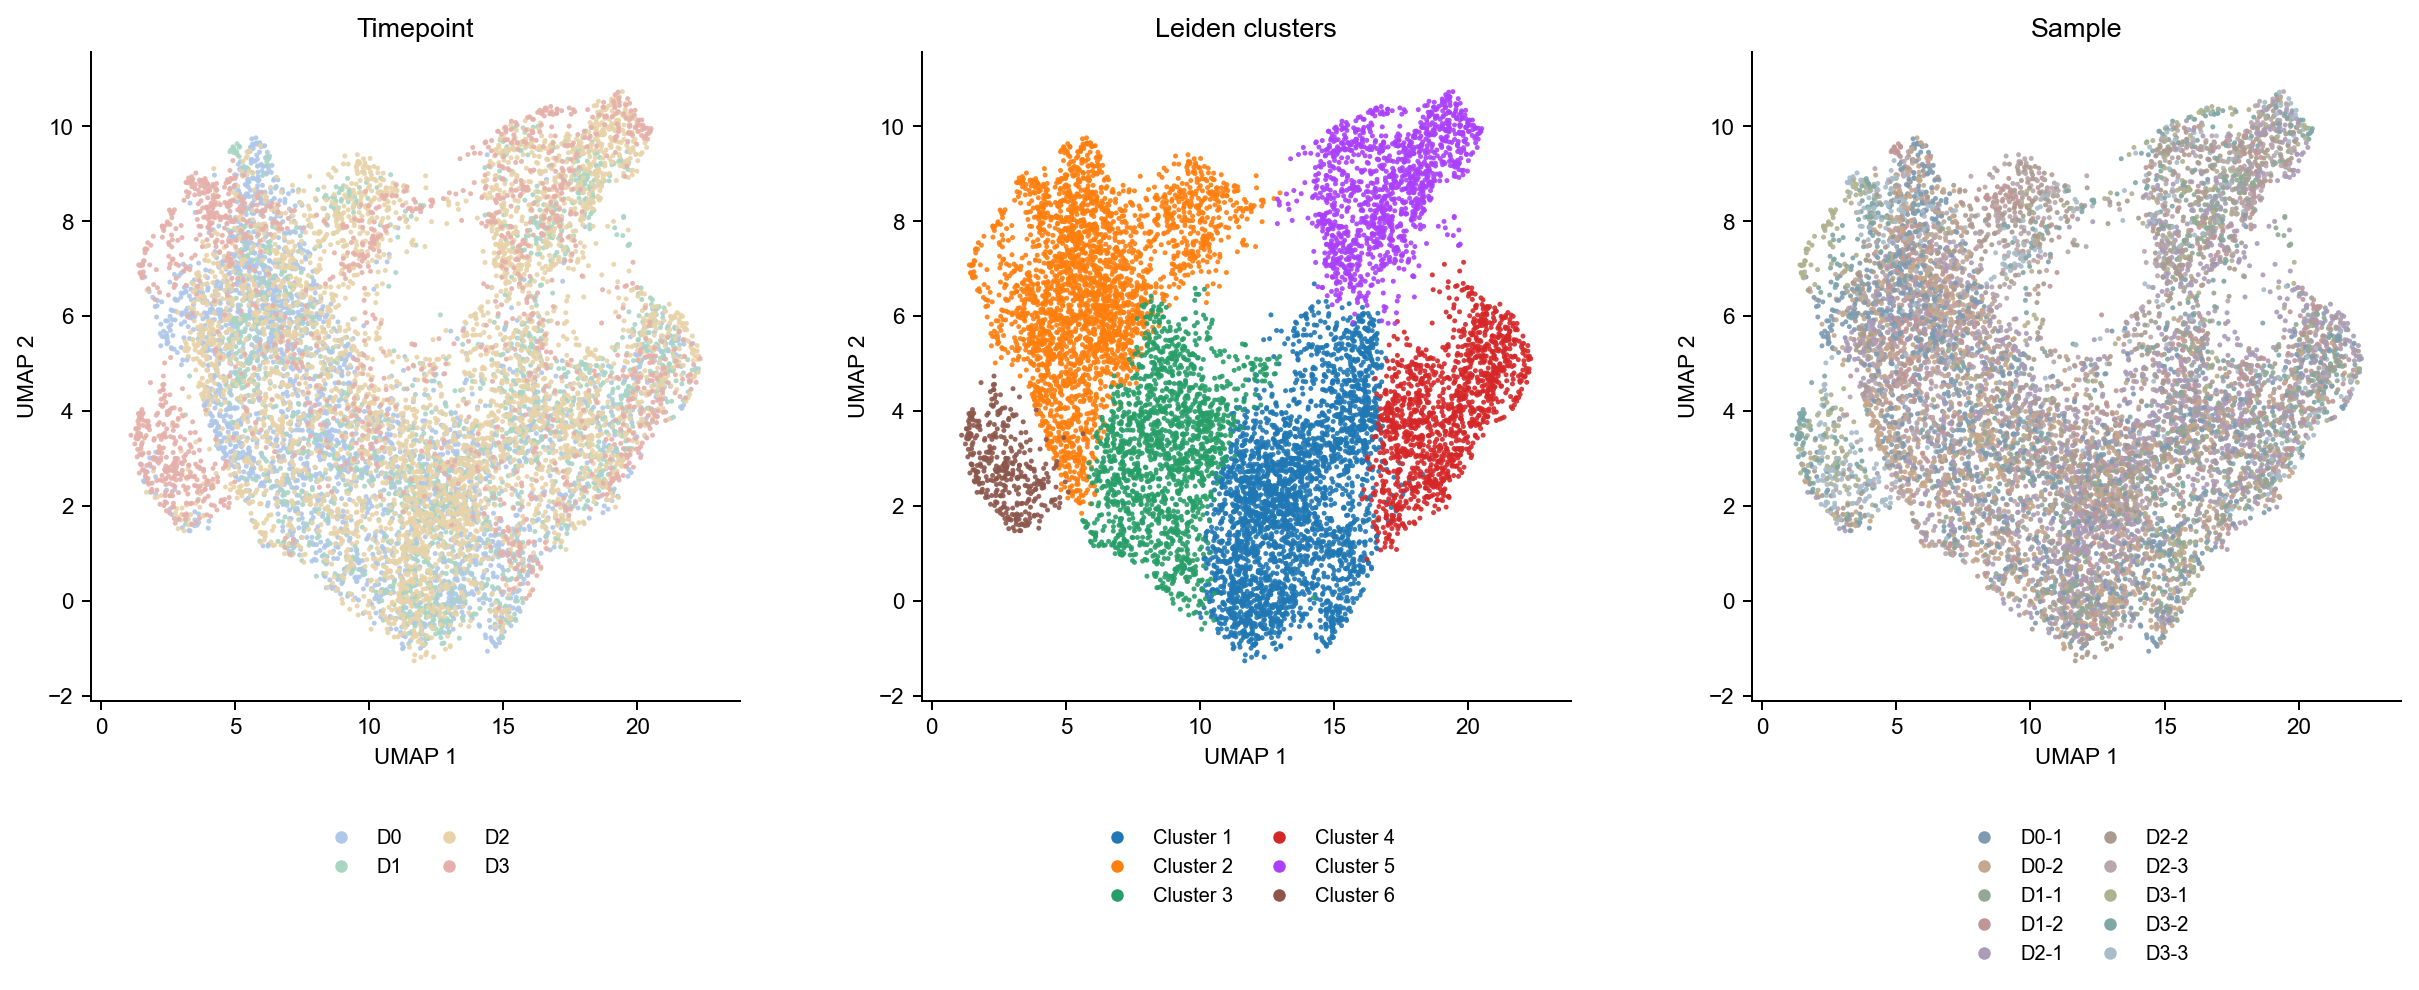

In [9]:
# 中文：图5e/f与S10a：在同一坐标范围并排展示三种UMAP着色。
# English: Figures 5e/f and S10a: show three UMAP colorings with shared coordinate limits.
set_style(9)
umap = umap_table[['UMAP1', 'UMAP2']].to_numpy()
padding = np.ptp(umap, axis=0) * .07
xlim = (umap[:, 0].min()-padding[0], umap[:, 0].max()+padding[0])
ylim = (umap[:, 1].min()-padding[1], umap[:, 1].max()+padding[1])
fig, axes = plt.subplots(1, 3, figsize=(13.8, 6.2))
fig.subplots_adjust(left=.055, right=.985, bottom=.32, top=.92, wspace=.28)
views = [('Timepoint', TIMEPOINTS, umap_table.timepoint.to_numpy(), TIME_COLORS),
         ('Leiden clusters', CLUSTERS, cluster_labels, CLUSTER_COLORS),
         ('Sample', SAMPLES, umap_table.sample_name.to_numpy(), SAMPLE_COLORS)]
for ax, (title, categories, labels, colors) in zip(axes, views):
    if title == 'Sample':
        order = np.random.default_rng(20261012).permutation(len(umap))
        point_colors = np.array([colors[label] for label in labels])
        ax.scatter(umap[order, 0], umap[order, 1], s=4, c=point_colors[order],
                   alpha=.9, edgecolors='none')
    else:
        for category in categories:
            use = labels == category
            ax.scatter(umap[use, 0], umap[use, 1], s=4, c=colors[category],
                       alpha=.9, edgecolors='none')
    assert sum(len(v.get_offsets()) for v in ax.collections) == len(umap)
    ax.set(xlim=xlim, ylim=ylim, xlabel='UMAP 1', ylabel='UMAP 2', title=title)
    ax.set_box_aspect(1)
    ax.spines[['top', 'right']].set_visible(False)
    handles = [Line2D([], [], linestyle='none', marker='o', markersize=5,
                      markerfacecolor=colors[k], markeredgecolor='none',
                      label=k[2:] if title=='Sample' else k) for k in categories]
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, -.17),
              ncol=2, frameon=False, fontsize=8, columnspacing=1.3)
save_figure(fig, 'Fig5ef_S10a_UMAP_overview')


In [10]:
# 中文：定义空间映射函数；圆点直径等于网格间距。
# English: Define spatial mapping; match each circle diameter to one grid spacing.
DISPLAY_COLORS = dict(zip(CLUSTERS, [(.122, .467, .706), (1., .498, .055),
    (.153, .620, .408), (.839, .153, .157), (.667, .251, .988), (.549, .337, .294)]))
DISPLAY_ALPHA = .899994
spatial_table = umap_table.copy()
spatial_table['original_spatial_x'] = raw.obs.col.to_numpy()
spatial_table['original_spatial_y'] = raw.obs.row.to_numpy()
assert not spatial_table.duplicated(['sample_name', 'original_spatial_x', 'original_spatial_y']).any()
def draw_sample(ax, table, sample, marker_area):
    sub = table.loc[table.sample_name.eq(sample)]
    plotted = 0
    for c in CLUSTERS:
        g = sub.loc[sub.cluster_r0_4.eq(c)]
        ax.scatter(g.original_spatial_x, g.original_spatial_y, color=DISPLAY_COLORS[c],
                   s=marker_area, marker="o", edgecolors="none", alpha=DISPLAY_ALPHA,
                   rasterized=False)
        plotted += len(g)
    assert plotted == len(sub)
    ax.set_xlim(0, 51)
    ax.set_ylim(51, 0)  # Raw row direction: row1 at top; numeric coordinates unchanged.
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([0, 10, 20, 30, 40, 50])
    ax.set_yticks([0, 10, 20, 30, 40, 50])
    ax.set_xlabel("Original spatial x (column)", fontsize=8)
    ax.set_ylabel("Original spatial y (row)", fontsize=8)
    ax.tick_params(labelsize=7, length=2, width=.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"{sample} | {len(sub):,} spots", fontsize=10, pad=7)

def legend_handles():
    return [Line2D([], [], color=DISPLAY_COLORS[c], marker="o", linestyle="none",
                   markeredgewidth=0, markersize=7, alpha=DISPLAY_ALPHA, label=c) for c in CLUSTERS]

def set_tangent_overview_markers(fig, axes):
    """Set each circle diameter to one grid pitch, using the final axes size.

    Matplotlib scatter areas are in points squared. For marker='o', sqrt(s)
    is the circle diameter in points. This conversion preserves tangency in
    the rendered figure without moving or merging spots.
    """
    fig.canvas.draw()
    geometry = []
    for ax in axes:
        xy = np.concatenate([np.asarray(c.get_offsets()) for c in ax.collections])
        nearest = cKDTree(xy).query(xy, k=2)[0][:, 1]
        pitch = float(nearest.min())
        assert np.isclose(pitch, 1.0), "Expected the existing unit-spaced spatial grid"
        origin, xstep, ystep = ax.transData.transform([[0, 0], [pitch, 0], [0, pitch]])
        dx_px = float(np.linalg.norm(xstep - origin))
        dy_px = float(np.linalg.norm(ystep - origin))
        assert np.isclose(dx_px, dy_px, rtol=0, atol=1e-8), "Axes must remain equal-aspect"
        diameter_pt = dx_px * 72.0 / fig.dpi
        for collection in ax.collections:
            # The circle marker path has unit width before scatter's size transform.
            bounds = collection.get_paths()[0].get_extents()
            assert np.isclose(bounds.width, 1.0) and np.isclose(bounds.height, 1.0)
            collection.set_sizes([diameter_pt ** 2])
        geometry.append(dict(sample=ax.get_title().split(" | ")[0], spots=len(xy),
                             grid_pitch=pitch, circle_diameter_data=pitch,
                             circle_diameter_pt=diameter_pt, marker_area_pt2=diameter_pt ** 2,
                             diameter_to_pitch_ratio=1.0))
    fig.canvas.draw()
    return geometry


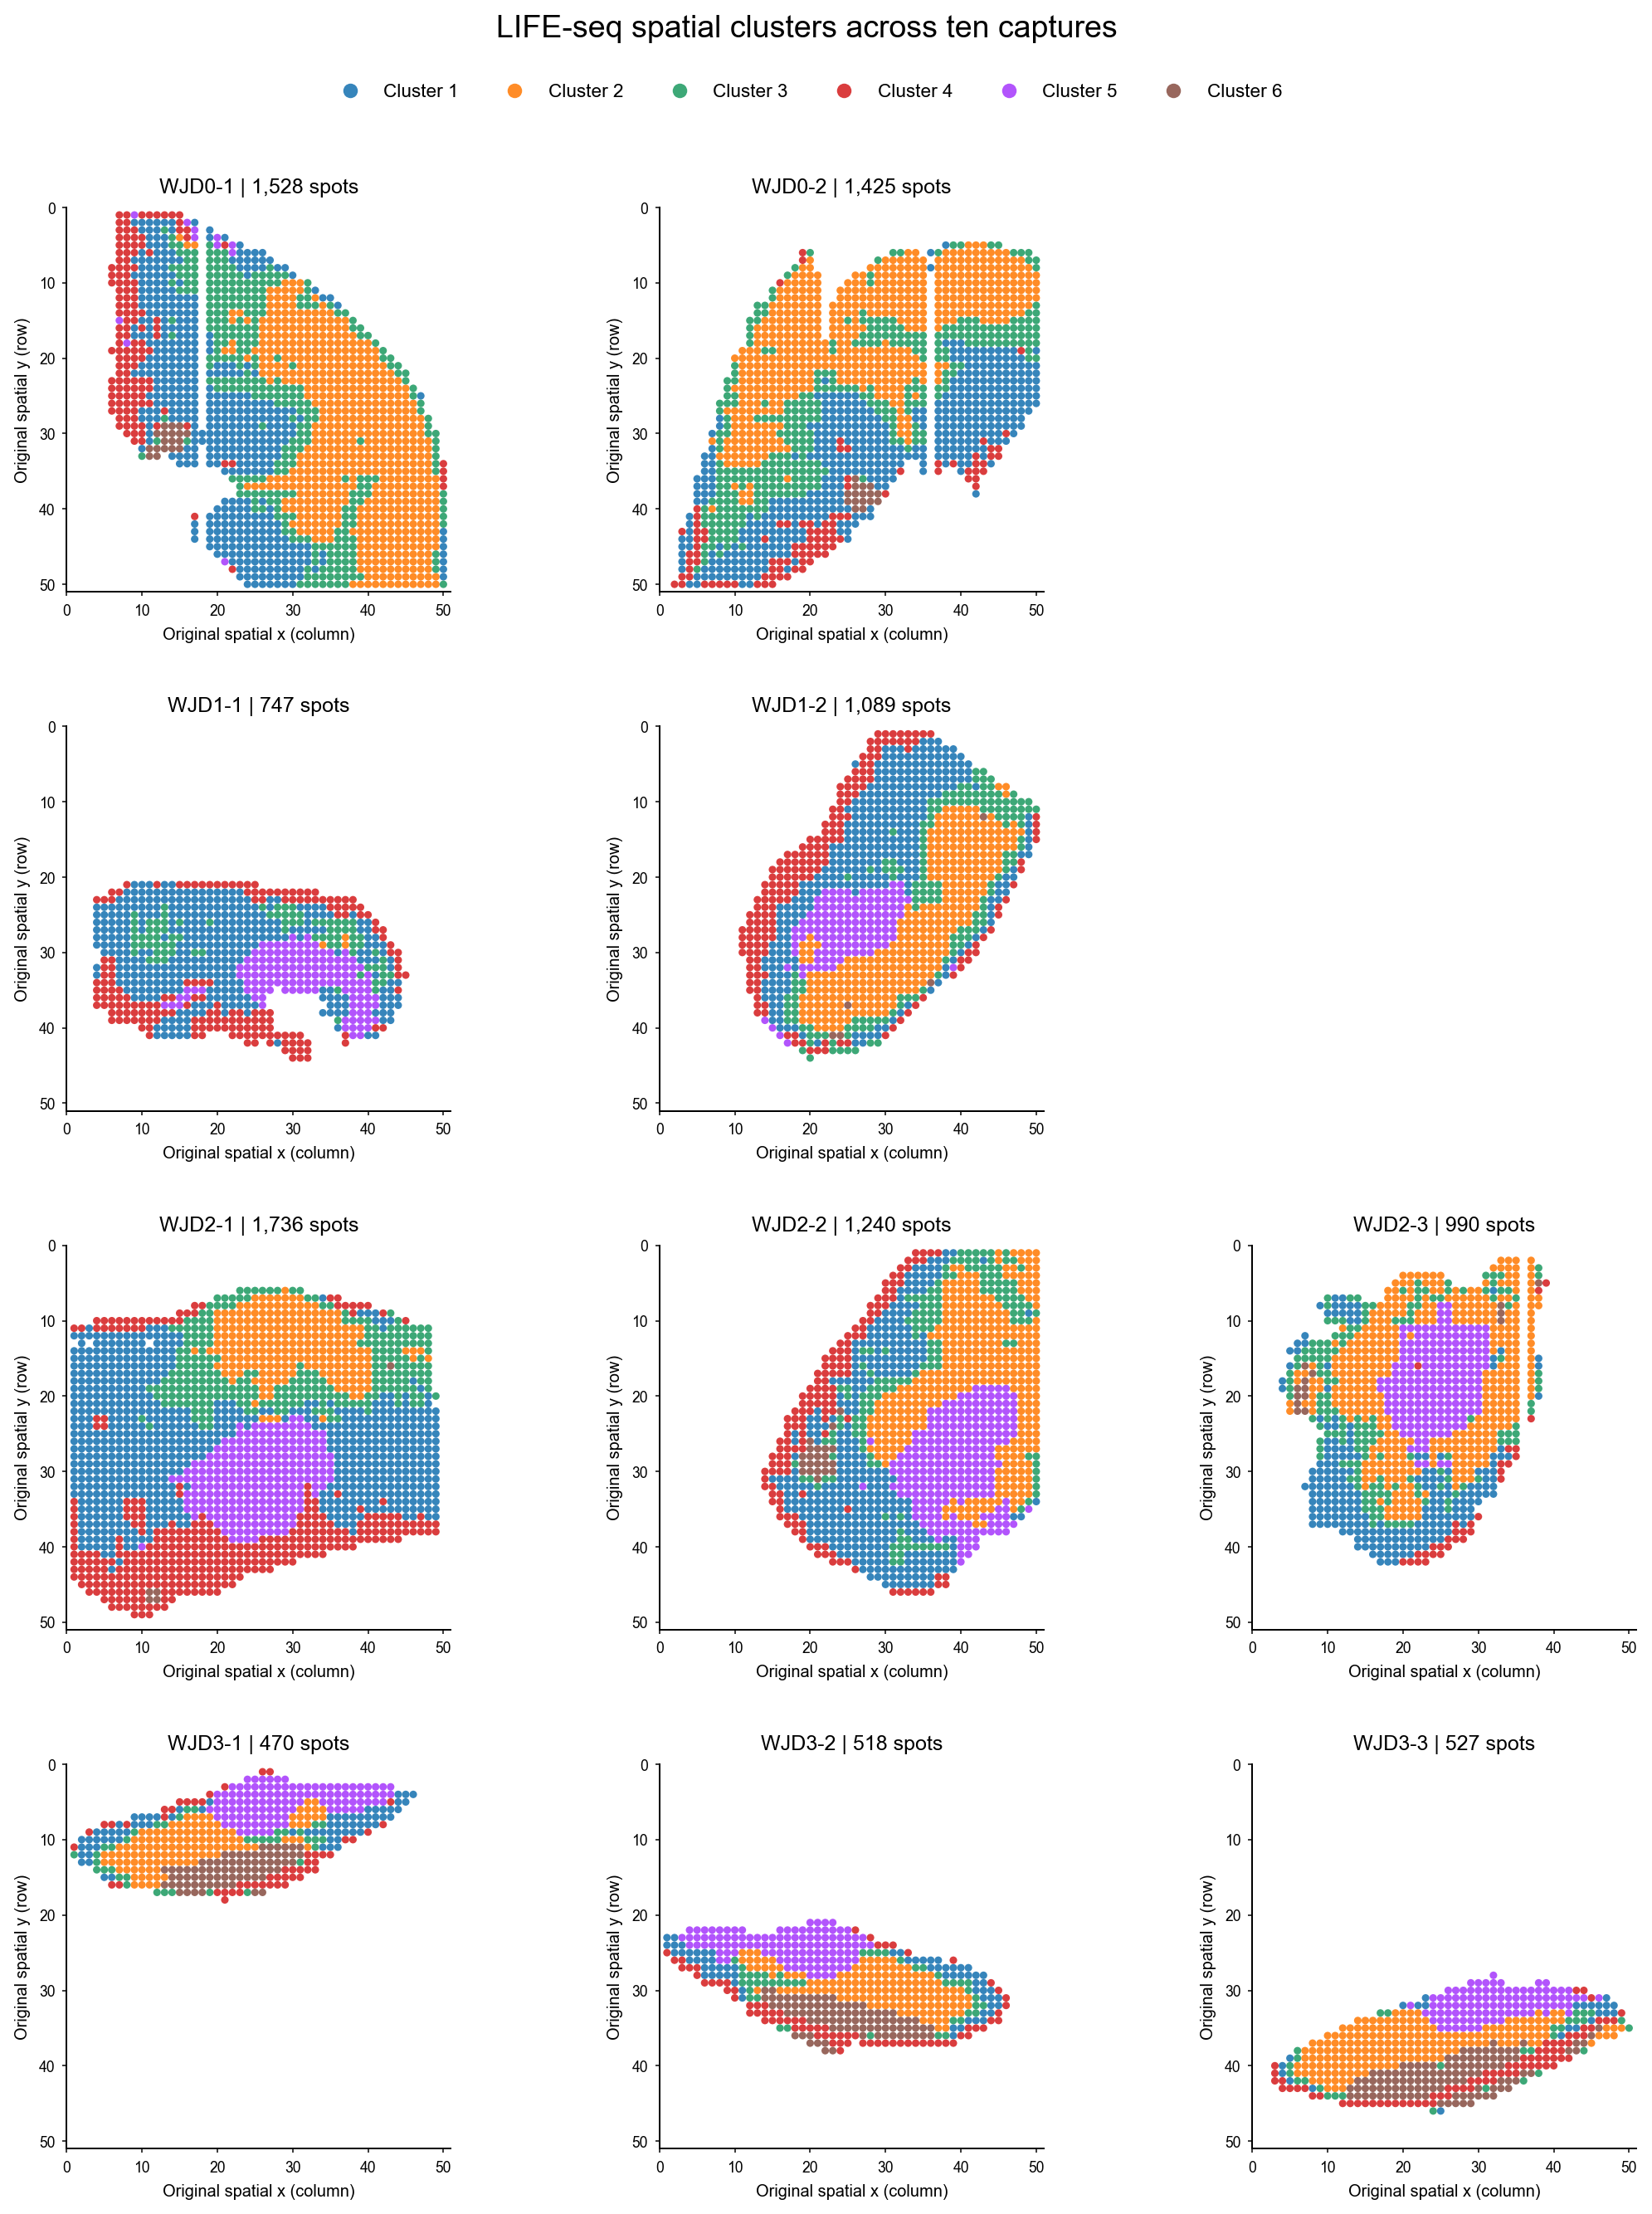

In [11]:
# 中文：图5g与S10b：按D0至D3排列全部十个样本的空间聚类。
# English: Figures 5g and S10b: arrange all ten spatial cluster maps by day.
set_style(9)
fig, grid = plt.subplots(4, 3, figsize=(12, 15.2))
fig.subplots_adjust(left=.065, right=.985, bottom=.045, top=.90, wspace=.28, hspace=.35)
active_axes = []
displayed_samples = []
for row, timepoint in enumerate(TIMEPOINTS):
    day_samples = [s for s in SAMPLES if SAMPLE_TIME[s] == timepoint]
    for col, ax in enumerate(grid[row]):
        if col >= len(day_samples):
            ax.set_visible(False)
            continue
        sample = day_samples[col]
        draw_sample(ax, spatial_table, sample, 5.8)
        active_axes.append(ax)
        displayed_samples.append(sample)
fig.suptitle('LIFE-seq spatial clusters across ten captures', fontsize=15, y=.985)
fig.legend(handles=legend_handles(), loc='upper center', bbox_to_anchor=(.5, .962),
           ncol=6, frameon=False, fontsize=9)
geometry = set_tangent_overview_markers(fig, active_axes)
assert displayed_samples == SAMPLES
assert sum(row['spots'] for row in geometry) == len(spatial_table)
save_figure(fig, 'Fig5g_S10b_spatial_clusters_all_10_samples')


## Figure 5h–j — Markers, composition and module enrichment / 标记基因、簇比例与模块富集

English: Marker dot area is the positive-spot fraction, and color is the gene-scaled mean expression. Cluster fractions are averaged equally across samples within each day. Module enrichment subtracts each sample background before equal-sample averaging and standardization across clusters.

中文：Marker点面积为阳性spot比例，颜色为逐基因缩放均值。时间点簇比例对各样本等权平均；模块富集扣除样本背景后等权汇总，并在簇间标准化。


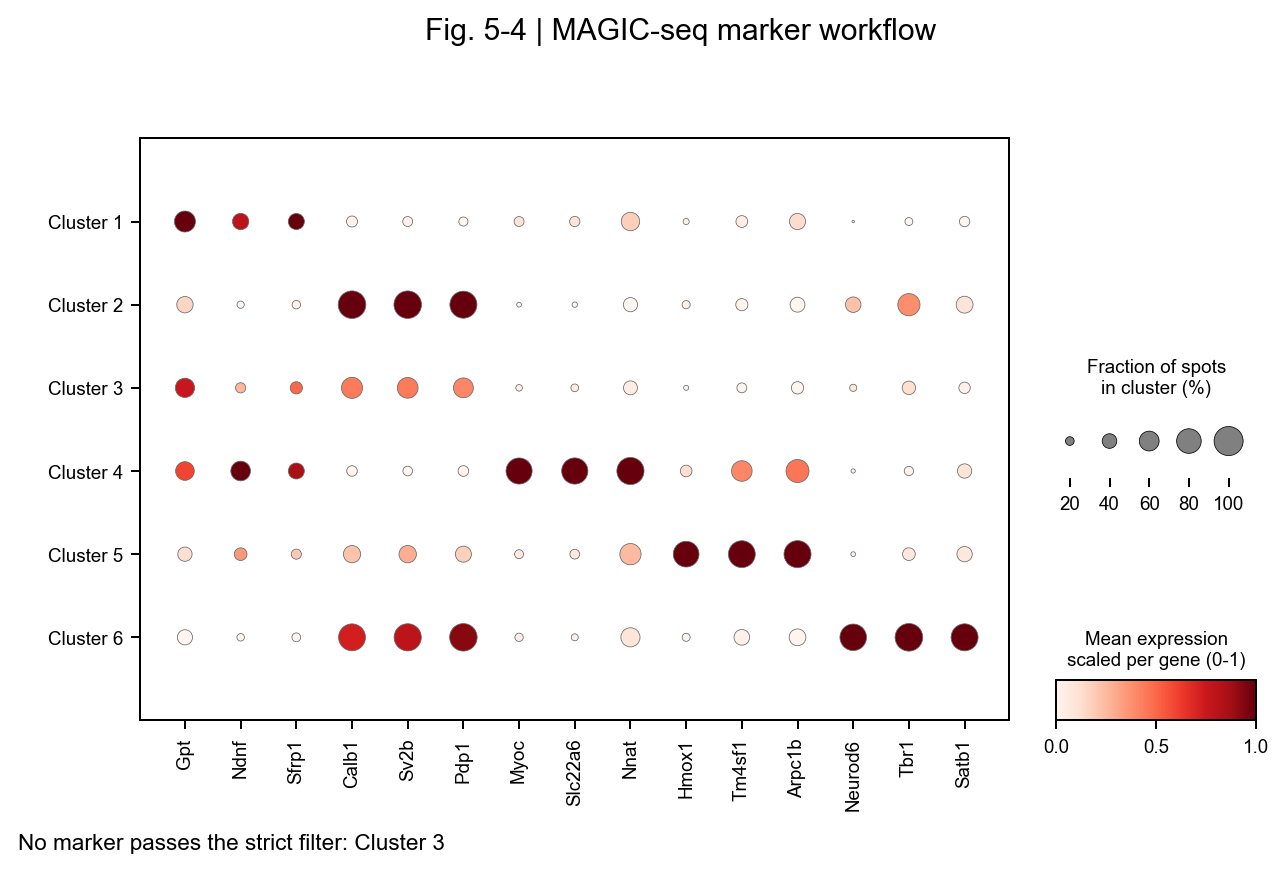

In [12]:
# 中文：图5h：点面积为阳性spot比例，颜色为逐基因缩放平均表达。
# English: Figure 5h: dot area shows the positive-spot fraction; color shows gene-scaled mean expression.
set_style()
# 中文：按随附marker表的顺序显示基因与六个簇。
# English: Display genes and six clusters in the supplied marker-table order.
markers = pd.read_csv(DATA / "marker_genes.csv").sort_values("display_order")
obs = umap_table.set_index("obs_name")[["sample_name", "timepoint", "cluster_r0_4"]].copy()
obs["cluster_r0_4"] = pd.Categorical(obs.cluster_r0_4, categories=CLUSTERS, ordered=True)
marker_adata = raw[:, gene_keep].copy()
sc.pp.normalize_total(marker_adata, target_sum=10000)
sc.pp.log1p(marker_adata)
matrix = marker_adata[:, markers.gene].X.copy()
assert matrix.shape == (len(obs), len(markers))
expression = sc.AnnData(matrix, obs=obs, var=pd.DataFrame(index=markers.gene.to_numpy()))
# 颜色为含零值的平均log-normalized表达逐基因缩放；点面积为表达>0的spot比例。
with mpl.rc_context({"font.size": 9}):
    dotplot = sc.pl.dotplot(expression, var_names=markers.gene.tolist(), groupby="cluster_r0_4",
        categories_order=CLUSTERS, use_raw=False, standard_scale="var", mean_only_expressed=False,
        expression_cutoff=0, cmap="Reds", swap_axes=False, dendrogram=False,
        return_fig=True, show=False, figsize=(8.0, 4.2), dot_min=0, dot_max=1)
    dotplot.legend(colorbar_title="Mean expression\nscaled per gene (0-1)",
                   size_title="Fraction of spots\nin cluster (%)")
    dotplot.style(dot_edge_color="#666666", dot_edge_lw=.3, largest_dot=135)
    dotplot.make_figure()
    dotplot.fig.suptitle("Fig. 5-4 | MAGIC-seq marker workflow", fontsize=12, y=1.04)
    empty_clusters = [c for c in CLUSTERS if not markers.cluster.eq(c).any()]
    if empty_clusters:
        dotplot.fig.text(.04, -.06, "No marker passes the strict filter: " + ", ".join(empty_clusters), fontsize=9)
    for ax in dotplot.get_axes().values():
        for collection in ax.collections:
            collection.set_rasterized(False)
            if isinstance(collection, mpl.collections.QuadMesh):
                collection.set_edgecolor("face")
    save_figure(dotplot.fig, "Fig5h_marker_dotplot")


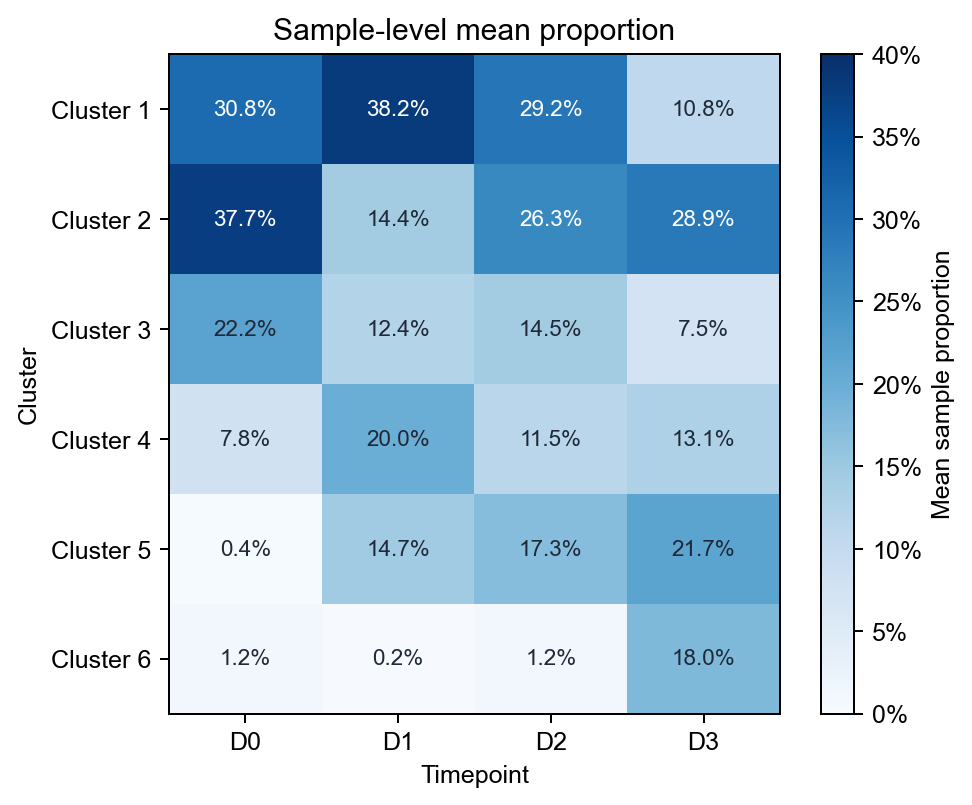

In [13]:
# 中文：图5i：样本等权的簇比例，不按spot总数加权。
# English: Figure 5i: equal-sample mean cluster proportions, without weighting by spot counts.
set_style()
# 中文：先计算样本内簇比例，再按时间点对样本等权平均。
# English: Calculate within-capture proportions before equal-capture averaging by day.
counts = pd.crosstab(umap_table.sample_name,umap_table.cluster_r0_4).reindex(
    index=SAMPLES,columns=CLUSTERS,fill_value=0)
sample_proportions = counts.div(counts.sum(axis=1),axis=0)
proportion = pd.DataFrame({
    t:sample_proportions.loc[[s for s in SAMPLES if SAMPLE_TIME[s]==t]].mean()
    for t in TIMEPOINTS}).reindex(CLUSTERS)
K = len(CLUSTERS)
fig, ax = plt.subplots(figsize=(5.5,4.6))
vmax = np.ceil(proportion.to_numpy().max()*20)/20
image = ax.pcolormesh(np.arange(5)-.5,np.arange(K+1)-.5,proportion.to_numpy(),
                     cmap="Blues",vmin=0,vmax=vmax,shading="flat",rasterized=False)
ax.set_xlim(-.5,3.5); ax.set_ylim(K-.5,-.5)
ax.set_xticks(range(4),TIMEPOINTS); ax.set_yticks(range(K),CLUSTERS)
ax.set(xlabel="Timepoint",ylabel="Cluster",title="Sample-level mean proportion")
for row in range(K):
    for col in range(4):
        value = proportion.iloc[row,col]
        ax.text(col,row,f"{value*100:.1f}%",ha="center",va="center",fontsize=9,
                color="white" if value>vmax*.56 else "#1F2937")
cb = fig.colorbar(image,ax=ax,label="Mean sample proportion",fraction=.055,pad=.06,
                 format=mpl.ticker.PercentFormatter(xmax=1,decimals=0))
cb.solids.set_rasterized(False); cb.solids.set_edgecolor("face")
fig.tight_layout()
save_figure(fig, "Fig5i_cluster_proportion")


In [14]:
# 中文：从原计数重算样本内模块富集，并按六簇标准化。
# English: Recompute within-sample module enrichment from counts and standardize across six clusters.
library = np.asarray(raw.X.sum(axis=1)).ravel()
ix = raw.var_names.get_indexer(module_table.gene)
x = (sparse.diags(10000 / library) @ raw.X[:, ix]).tocsr()
x.data = np.log1p(x.data)
module_index = pd.Categorical(module_table.module, categories=MODULES).codes
gene_weights = sparse.csr_matrix((1 / np.array(EXPECTED_SIZES)[module_index], (np.arange(len(module_table)), module_index)), shape=(len(module_table), 5))
spot_scores = (x @ gene_weights).toarray()
rows = []
for sample in SAMPLES:
    use = sample_labels == sample
    baseline = spot_scores[use].mean(axis=0)
    for cluster in CLUSTERS:
        subset = use & (cluster_labels == cluster)
        values = spot_scores[subset].mean(axis=0) if subset.any() else np.full(5, np.nan)
        for j, module in enumerate(MODULES):
            rows.append({'sample_name': sample, 'cluster': cluster, 'module': module,
                'n_spots': int(subset.sum()), 'mean_expression': values[j], 'contrast': values[j] - baseline[j]})
cluster_module_samples = pd.DataFrame(rows)
contrast = cluster_module_samples.groupby(['cluster', 'module']).contrast.mean().unstack().loc[CLUSTERS, MODULES]
uncentered = cluster_module_samples.groupby(['cluster', 'module']).mean_expression.mean().unstack().loc[CLUSTERS, MODULES]
primary = (contrast - contrast.mean()) / contrast.std(ddof=0)
uncentered_z = (uncentered - uncentered.mean()) / uncentered.std(ddof=0)
lim = float(np.ceil(max(np.abs(primary.to_numpy()).max(), np.abs(uncentered_z.to_numpy()).max()) * 2) / 2)
assert cluster_module_samples.query('cluster == "Cluster 5" and module == "Module 2"').contrast.notna().sum() == 9
display(primary.round(3))


module,Module 1,Module 2,Module 3,Module 4,Module 5
cluster,,,,,
Cluster 1,-1.051,-0.367,-0.750,-1.573,-1.214
Cluster 2,1.503,-0.751,-0.352,1.109,1.406
Cluster 3,1.073,-0.812,-0.786,-0.623,-0.090
Cluster 4,-0.873,0.840,0.226,-0.640,-1.068
Cluster 5,-0.831,1.838,2.108,0.811,-0.199
Cluster 6,0.178,-0.747,-0.446,0.916,1.166


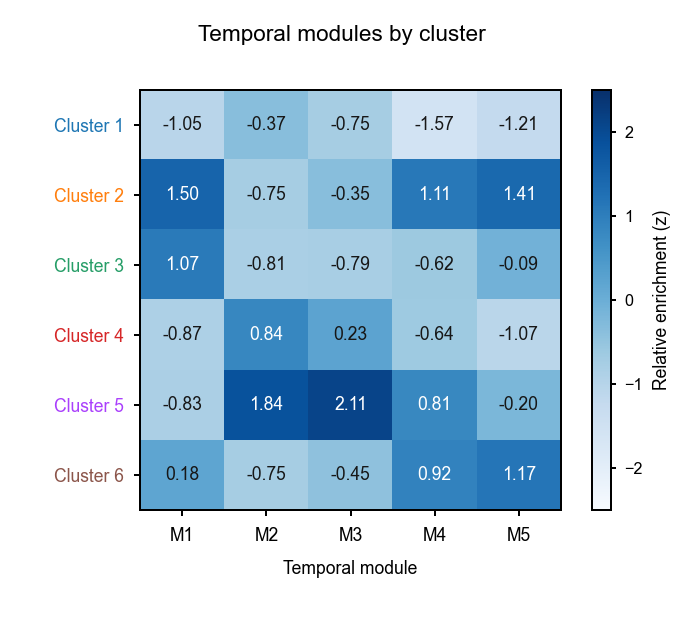

In [15]:
# 中文：图5j：显示簇与模块的标准化富集。
# English: Figure 5j: display standardized cluster–module enrichment.
set_style(8)
palette = CLUSTER_COLORS
def draw(ax,matrix,limit,ylab=None,xlab=None,font=8,cmap='RdBu_r'):
 im=ax.imshow(matrix.to_numpy(),vmin=-limit,vmax=limit,cmap=cmap,interpolation='nearest',aspect='auto')
 ax.set_xticks(range(5),MODULES if xlab is None else xlab);ax.set_yticks(range(6),CLUSTERS if ylab is None else ylab)
 ax.tick_params(axis='both',length=0,pad=7)
 for tick,c in zip(ax.get_yticklabels(),CLUSTERS):tick.set_color(palette[c])
 for i in range(6):
  for j in range(5):
   value=matrix.iloc[i,j]
   if np.isfinite(value):
    if cmap=='Blues':
     rgb=im.cmap(im.norm(value))[:3]
     dark_fill=np.dot(rgb,[.2126,.7152,.0722])<.54
    else:dark_fill=abs(value)>.61*limit
    ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=font,color='white' if dark_fill else '#171717')
   else:ax.text(j,i,'NA',ha='center',va='center',fontsize=font,color='#555555')
 for spine in ax.spines.values():spine.set_visible(False)
 return im
fig,ax=plt.subplots(figsize=(3.8,3.5))
left,right,bottom=.205,.82,.19
top=bottom+(right-left)*fig.get_figwidth()/fig.get_figheight()
fig.subplots_adjust(left=left,right=right,bottom=bottom,top=top)
im=draw(ax,primary,lim,xlab=[f'M{i}' for i in range(1,6)],font=7,cmap='Blues')
for spine in ax.spines.values():
 spine.set_visible(True);spine.set_color('black');spine.set_linewidth(.8)
ax.tick_params(axis='both',pad=4,labelsize=7,length=2.5,width=.8,bottom=True,left=True,top=False,right=False)
ax.set_xlabel('Temporal module',fontsize=7,labelpad=6)
pos=ax.get_position();cax=fig.add_axes([.865,pos.y0,.028,pos.height]);cb=fig.colorbar(im,cax=cax)
cb.outline.set_edgecolor('black');cb.outline.set_linewidth(.8)
cb.ax.tick_params(labelsize=6.5,length=2);cb.set_label('Relative enrichment (z)',fontsize=7,labelpad=4)
fig.suptitle('Temporal modules by cluster',fontsize=9,y=.96)
fig.canvas.draw();box=ax.get_window_extent();cbox=cax.get_window_extent()
assert abs(box.width-box.height)<.01 and abs(box.y0-cbox.y0)<.01 and abs(box.y1-cbox.y1)<.01

save_figure(fig, 'Fig5j_cluster_module_enrichment', tight=False)


## Figure S8c — Transcriptomic correlations / 转录组相关性

English: Pearson correlations use log2(sample gene-total counts + 1) for 22,261 Gene IDs shared across all ten samples. Density coloring uses all gene points.

中文：以十样本共同的22,261个Gene ID计算log2(样本总计数+1)的Pearson相关性，全部基因点用于密度着色。


In [16]:
# 中文：按Gene ID汇总和对齐，重算45对Pearson R及着色密度。
# English: Aggregate and align Gene IDs; recompute 45 Pearson correlations and color densities.
def binned_gaussian_density(xy,bandwidth=.5,step=.025):
    """Fast 2D Gaussian KDE approximation for colors, retaining every gene.

    Histogram spacing is 1/20 of the reference bandwidth. Five-bandwidth
    padding prevents artificial reflection at the zero-count boundaries.
    Correlations are calculated independently and never use this approximation.
    """
    lo=np.floor(xy.min(axis=0)/step)*step-5*bandwidth
    hi=np.ceil(xy.max(axis=0)/step)*step+5*bandwidth+step
    edges=[np.arange(a,b+step*.5,step) for a,b in zip(lo,hi)]
    hist,_,_=np.histogram2d(xy[:,0],xy[:,1],bins=edges)
    smooth=gaussian_filter(hist.astype(float),sigma=bandwidth/step,mode='constant',cval=0,truncate=5.)
    coordinates=(xy-lo)/step-.5
    density=map_coordinates(smooth,coordinates.T,order=1,mode='constant',cval=0,prefilter=False)
    return density/(len(xy)*step**2)

gene_frames = []
for sample in SAMPLES:
    use = sample_labels == sample
    batch = raw.obs.loc[use, 'batch'].astype(str).unique()
    assert len(batch) == 1
    gene_ids = raw.var['Gene_id-' + batch[0]].astype('string')
    valid = gene_ids.notna() & gene_ids.ne('')
    assert gene_ids[valid].is_unique
    totals = np.asarray(raw.X[use].sum(axis=0, dtype=np.float64)).ravel()
    assert np.all(totals[~valid.to_numpy()] == 0)
    gene_frames.append(pd.DataFrame({'gene_id': gene_ids[valid].to_numpy(), sample: totals[valid.to_numpy()]}))
common_counts = gene_frames[0]
for frame in gene_frames[1:]:
    common_counts = common_counts.merge(frame, on='gene_id', how='inner', validate='one_to_one', sort=False)
assert len(common_counts) == 22261
correlation_values = np.log2(common_counts[SAMPLES].to_numpy(float) + 1)
R = np.corrcoef(correlation_values, rowvar=False)
density_cache = {}
for col in range(10):
    for row in range(col + 1, 10):
        np.testing.assert_allclose(R[row, col], stats.pearsonr(correlation_values[:, col], correlation_values[:, row]).statistic, atol=1e-12)
        density_cache[f'pair_{col}_{row}'] = binned_gaussian_density(correlation_values[:, [col, row]])
print('Shared Gene IDs / 共同基因ID:', len(common_counts))
print('Pearson R range / 范围:', np.round(R[np.triu_indices(10, 1)].min(), 6), np.round(R[np.triu_indices(10, 1)].max(), 6))


Shared Gene IDs / 共同基因ID: 22261
Pearson R range / 范围: 0.90971 0.985955


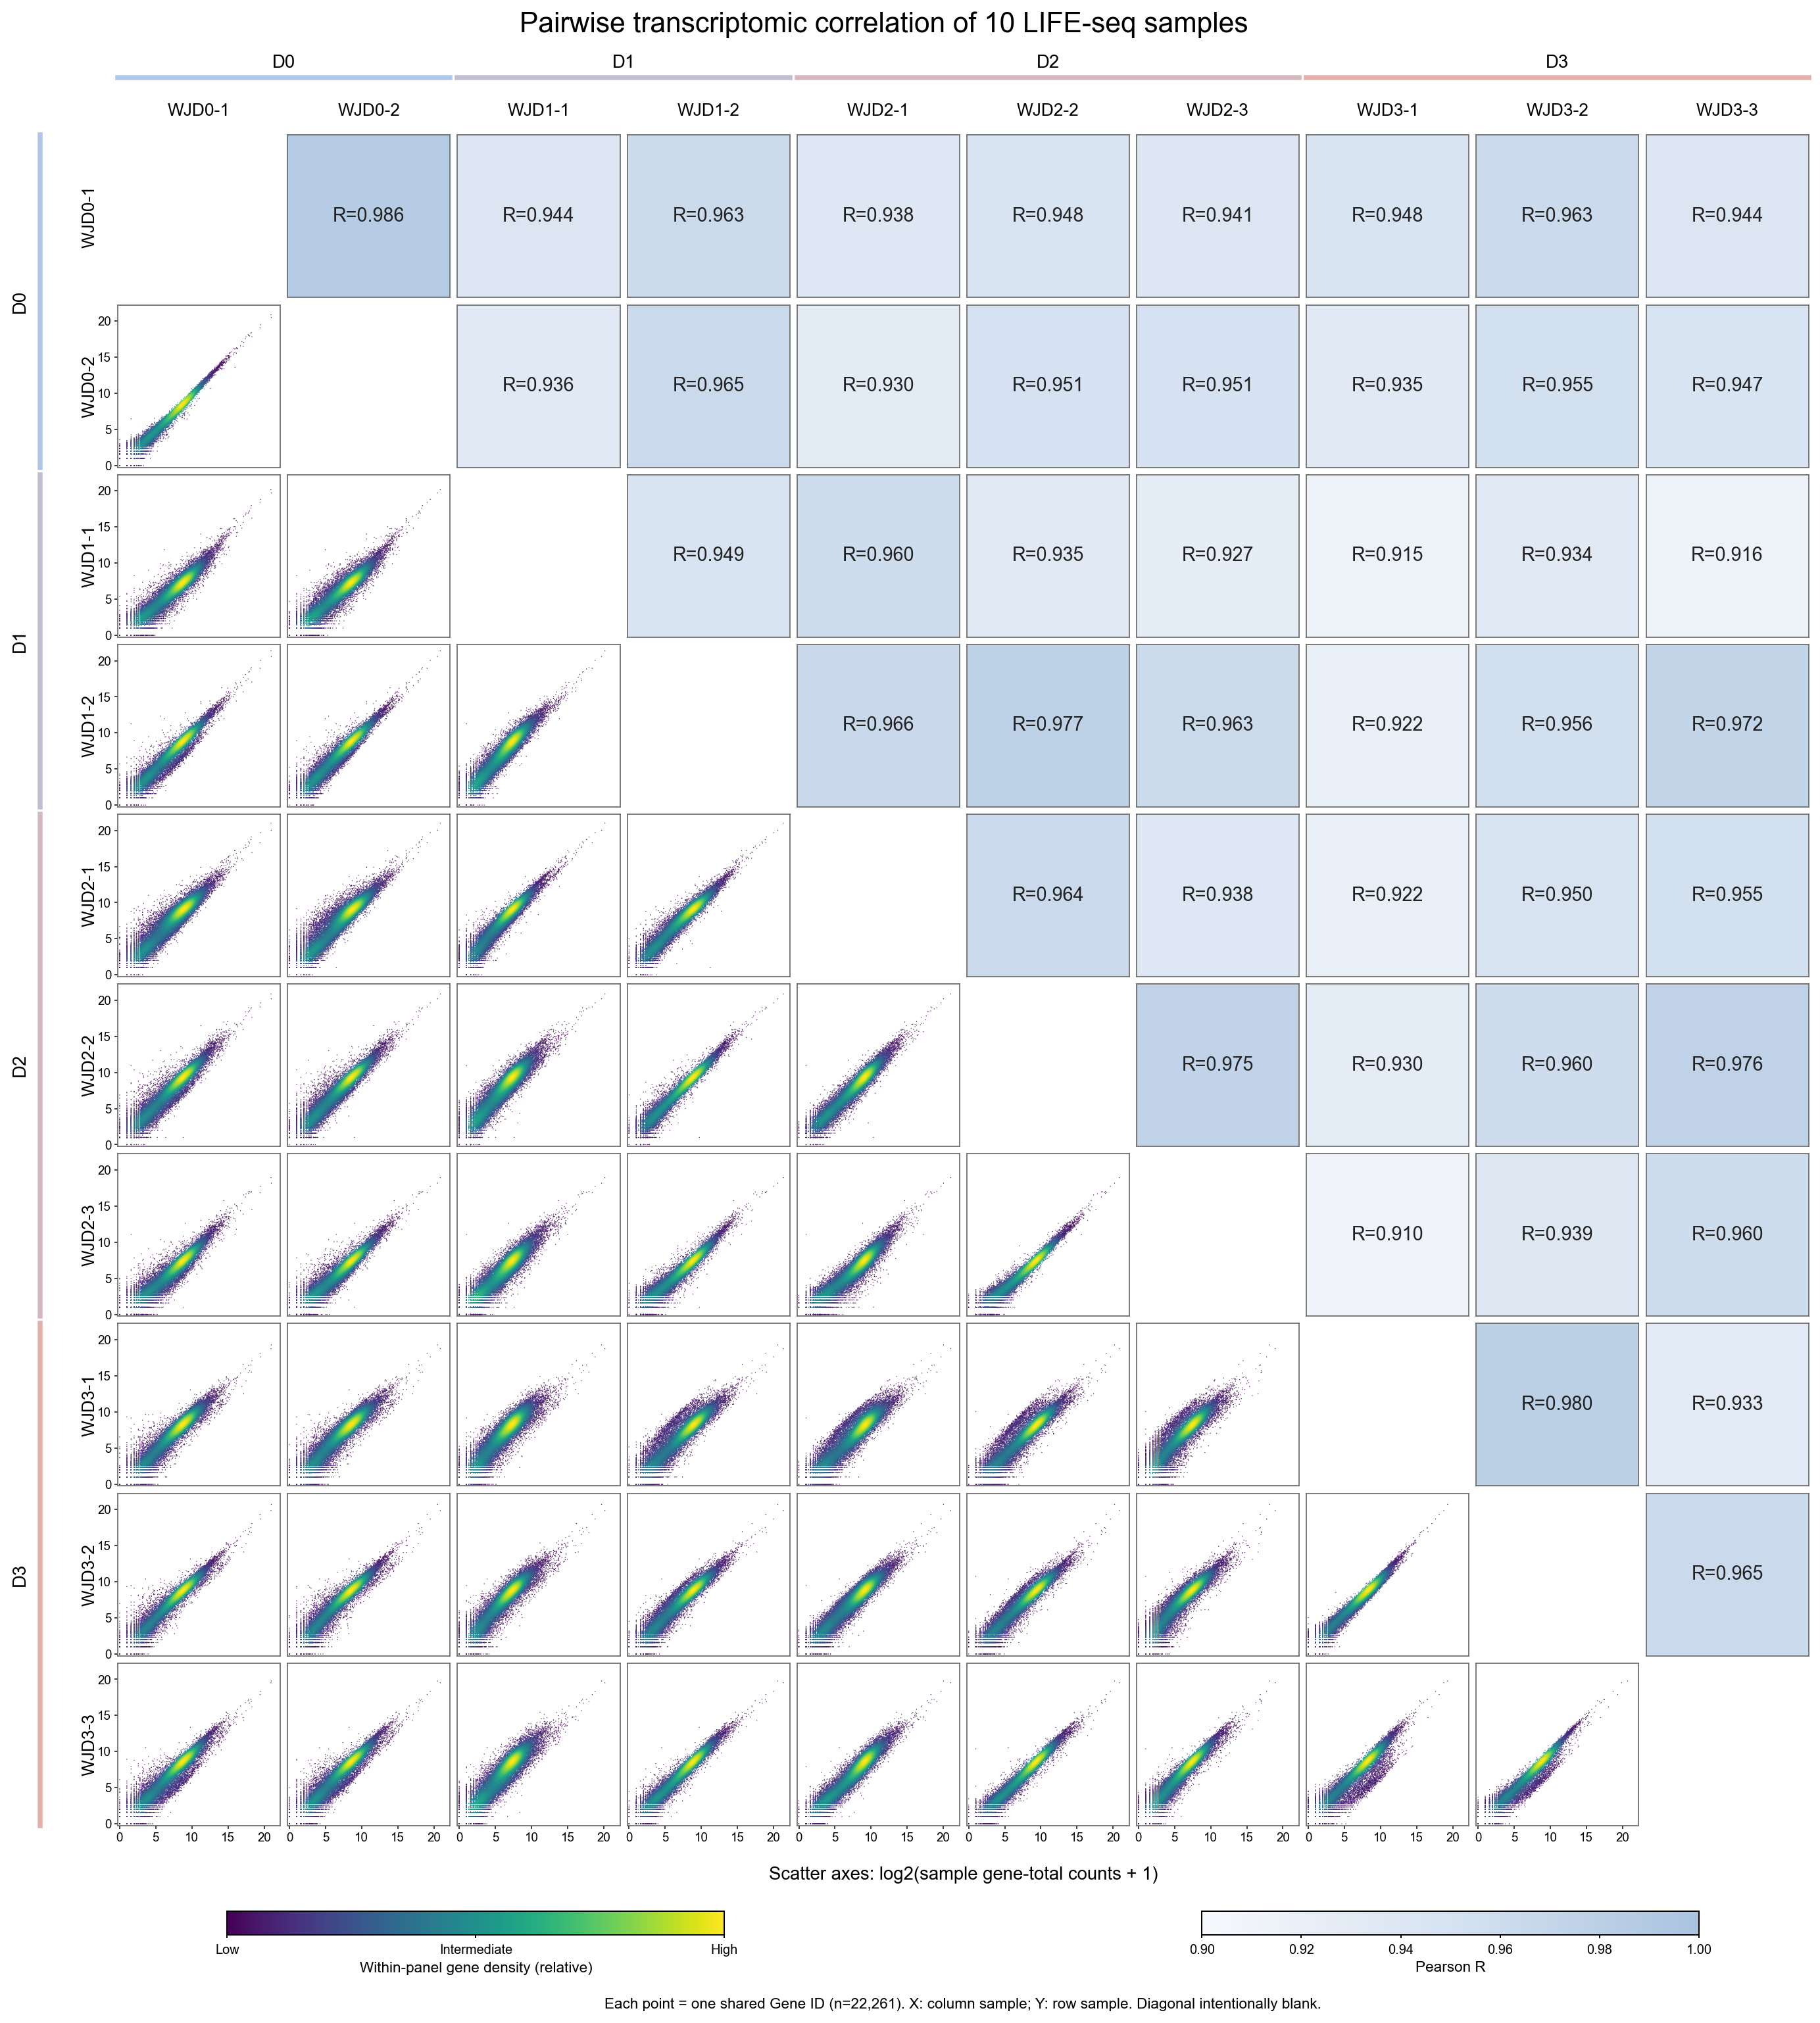

In [17]:
# 中文：图S8c：下三角密度散点、上三角R值、对角线留空。
# English: Figure S8c: density scatter below, Pearson R above, and an empty diagonal.
set_style()
values = correlation_values
fig=plt.figure(figsize=(16.8,16.8))
gs=fig.add_gridspec(10,10,left=.115,right=.965,bottom=.10,top=.95,wspace=.045,hspace=.045)
# Match get_adata: viridis with linear density normalization per panel.
density_map=mpl.colormaps['viridis']
correlation_map=LinearSegmentedColormap.from_list('correlation_pale_blue',['#f6f8fc','#d7e3f1','#aac3df'])
minimum=float(R[np.triu_indices(10,1)].min())
R_norm=Normalize(vmin=max(-1.,np.floor(minimum*20)/20),vmax=1.)
density_norm=Normalize(vmin=0,vmax=1)
vmax=float(np.ceil(values.max()/2)*2)
ticks=np.arange(0,vmax+.01,5.)
cache=density_cache
geometry=[];top_positions=[];left_positions=[]
for row in range(10):
    for col in range(10):
        ax=fig.add_subplot(gs[row,col]);ax.set_box_aspect(1)
        pos=ax.get_position()
        if row==0:top_positions.append((pos.x0+pos.x1)/2)
        if col==0:left_positions.append((pos.y0+pos.y1)/2)
        if row==col:
            ax.set_axis_off();geometry.append({'row':row,'col':col,'kind':'blank'})
            continue
        for spine in ax.spines.values():spine.set_color('#6c6c6c');spine.set_linewidth(.7)
        if row<col:
            ax.set_facecolor(correlation_map(R_norm(R[row,col])))
            ax.set_xticks([]);ax.set_yticks([])
            ax.text(.5,.5,f'R={R[row,col]:.3f}',transform=ax.transAxes,ha='center',va='center',fontsize=11.5,color='#222222')
            geometry.append({'row':row,'col':col,'kind':'R','value':float(R[row,col])})
        else:
            d=cache[f'pair_{col}_{row}'];order=np.argsort(d,kind='stable')
            # All common genes are displayed; rasterize the large point layers only.
            relative_density=(d-d.min())/(d.max()-d.min()) if d.max()>d.min() else np.zeros_like(d)
            ax.scatter(values[order,col],values[order,row],c=relative_density[order],cmap=density_map,norm=density_norm,
                s=.32,edgecolors='none',linewidths=0,alpha=.85,rasterized=True)
            ax.set_xlim(-.25,vmax+.25);ax.set_ylim(-.25,vmax+.25)
            ax.set_xticks(ticks if row==9 else []);ax.set_yticks(ticks if col==0 else [])
            ax.tick_params(labelsize=7.5,length=2,width=.6,pad=2)
            assert len(ax.collections[0].get_offsets())==len(values)
            geometry.append({'row':row,'col':col,'kind':'scatter','n_points':len(values),
                'x_sample':SAMPLES[col],'y_sample':SAMPLES[row]})

for x,s in zip(top_positions,SAMPLES):fig.text(x,.958,s,ha='center',va='bottom',fontsize=10.5)
for y,s in zip(left_positions,SAMPLES):fig.text(.105,y,s,ha='right',va='center',rotation=90,fontsize=10.5)
# Timepoint brackets group samples while the diagonal remains empty.
groups=[(0,2),(2,4),(4,7),(7,10)]
for (start,end),tp,color in zip(groups,TIMEPOINTS,['#afc7e8','#c1bfd3','#d4b8bf','#e6b0aa']):
    first=gs[0,start].get_position(fig);last=gs[0,end-1].get_position(fig)
    fig.add_artist(plt.Line2D([first.x0,last.x1],[.979,.979],transform=fig.transFigure,color=color,lw=3))
    fig.text((first.x0+last.x1)/2,.982,tp,ha='center',va='bottom',fontsize=11)
    top=gs[start,0].get_position(fig).y1;bottom=gs[end-1,0].get_position(fig).y0
    fig.add_artist(plt.Line2D([.076,.076],[bottom,top],transform=fig.transFigure,color=color,lw=3))
    fig.text(.066,(bottom+top)/2,tp,rotation=90,ha='center',va='center',fontsize=11)
fig.suptitle('Pairwise transcriptomic correlation of 10 LIFE-seq samples',y=1.012,fontsize=17,fontweight='normal')
fig.text(.54,.073,'Scatter axes: log2(sample gene-total counts + 1)',ha='center',fontsize=11)
cax_d=fig.add_axes([.17,.045,.25,.012])
cb_d=fig.colorbar(mpl.cm.ScalarMappable(norm=density_norm,cmap=density_map),cax=cax_d,orientation='horizontal')
cb_d.set_ticks([0,.5,1]);cb_d.set_ticklabels(['Low','Intermediate','High']);cb_d.ax.tick_params(labelsize=8,length=2)
cb_d.set_label('Within-panel gene density (relative)',fontsize=9,labelpad=3)
cax_r=fig.add_axes([.66,.045,.25,.012])
cb_r=fig.colorbar(mpl.cm.ScalarMappable(norm=R_norm,cmap=correlation_map),cax=cax_r,orientation='horizontal')
cb_r.ax.tick_params(labelsize=8,length=2);cb_r.set_label('Pearson R',fontsize=9,labelpad=3)
for cb in [cb_d,cb_r]:cb.solids.set_rasterized(False);cb.solids.set_edgecolor('face')
fig.text(.54,.008,f'Each point = one shared Gene ID (n={len(values):,}). X: column sample; Y: row sample. Diagonal intentionally blank.',ha='center',fontsize=9)
assert sum(g['kind']=='scatter' for g in geometry)==45
assert sum(g['kind']=='R' for g in geometry)==45
assert sum(g['kind']=='blank' for g in geometry)==10

save_figure(fig, 'FigS8c_sample_correlation')


## Figure S9a–d — Differential expression / 差异表达

English: The included statistics contain 20,011 tested genes per contrast from a four-group filterByExpr → TMM → limma-voom model. Contrasts are later minus earlier; thresholds are BH-adjusted P < 0.05 and |log2FC| > 1. This section uses fitted statistics and does not refit the R model.

中文：data提供四组filterByExpr→TMM→limma-voom模型的完整统计，每比较20,011个基因。比较方向为后期减前期，阈值为BH校正P<0.05且|log2FC|>1；此处读取拟合结果。


In [18]:
# 中文：载入完整差异结果并计算BH校正与上下调数量。
# English: Load differential-expression statistics and calculate BH correction and up/down counts.
COMPARISONS = [(1, 'D0', 'D1'), (2, 'D1', 'D2'), (3, 'D2', 'D3'), (4, 'D0', 'D3')]
SAMPLES_BY_TIME = {t: [s for s in SAMPLES if SAMPLE_TIME[s] == t] for t in TIMEPOINTS}
RESULTS, SUMMARIES = {}, []
all_de = pd.read_csv(DATA / 'S9_differential_expression.csv.gz', float_precision='round_trip')
expected_de = [(72, 1), (9, 0), (21, 88), (490, 505)]
for (i, earlier, later), (up, down) in zip(COMPARISONS, expected_de):
    key = earlier + '_vs_' + later
    result = all_de.loc[all_de.comparison.eq(key)].copy()
    assert len(result) == 20011 and result.names.is_unique
    assert set(result.names).issubset(raw.var_names[gene_keep])
    np.testing.assert_allclose(result.pvals_adj, multipletests(result.pvals, method='fdr_bh')[1], rtol=1e-10, atol=1e-14)
    result['Significance'] = 'NS'
    result.loc[(result.logfoldchanges > 1) & (result.pvals_adj < .05), 'Significance'] = 'Up'
    result.loc[(result.logfoldchanges < -1) & (result.pvals_adj < .05), 'Significance'] = 'Down'
    result['neg_log10_padj'] = -np.log10(result.pvals_adj)
    result['y_plot'] = np.minimum(result.neg_log10_padj, 200)
    assert (result.Significance.eq('Up').sum(), result.Significance.eq('Down').sum()) == (up, down)
    RESULTS[key] = result
    print(key, 'Up:', up, 'Down:', down)
Y_CAP, Y_LIMIT = 200., 4.
COLORS = {'Up': '#d62728', 'Down': '#1f77b4', 'NS': '#e0e0e0'}
LABEL_CANDIDATES = {
    'Myeloid': ['Lyz2', 'Spp1', 'Cd68', 'Ctss', 'Tyrobp', 'Trem2', 'Cst7', 'Apoe'],
    'Astrocyte': ['Gfap', 'Vim', 'Lcn2', 'Serpina3n', 'C3', 'Clu'],
    'IFN': ['Cxcl10', 'Ifitm3', 'Isg15', 'Irf7'],
    'Remodeling': ['Fn1', 'Lgals1'], 'Heme/stress': ['Hmox1'],
    'Neuronal': ['Snap25', 'Syt1', 'Syp', 'Syn1', 'Syn2', 'Stx1a', 'Stx1b', 'Vamp2',
                'Stxbp1', 'Rab3a', 'Cplx1', 'Cplx2', 'Sv2a', 'Dlg4', 'Gria1', 'Gria2',
                'Grin1', 'Grin2a', 'Shank1', 'Nrxn1', 'Ddn', 'Nefm']}
LABEL_EXCLUDE = re.compile(r'^mt-|^Gm|-ps|Rik$|^Hba-|^Hbb-|^Rp[sl]\d+', re.IGNORECASE)
rrna = np.zeros(raw.n_vars, dtype=bool)
for col in [c for c in raw.var if c.startswith('Gene_type')]:
    rrna |= raw.var[col].astype(str).str.fullmatch('rRNA', case=False).to_numpy()
RRNA_LABEL_GENES = set(raw.var_names[rrna])


D0_vs_D1 Up: 72 Down: 1
D1_vs_D2 Up: 9 Down: 0
D2_vs_D3 Up: 21 Down: 88
D0_vs_D3 Up: 490 Down: 505


In [19]:
# 中文：定义火山图及基因标签布局。
# English: Define volcano plots and gene-label placement.
def select_gene_labels(result,category,n=5):
    eligible=result.loc[(result.Significance==category)&(result.logfoldchanges.abs()<=8)].copy()
    eligible=eligible.loc[~eligible.names.map(lambda g:bool(LABEL_EXCLUDE.search(g)))]
    eligible=eligible.loc[~eligible.names.isin(RRNA_LABEL_GENES)]
    eligible["abs_score"]=eligible.scores.abs()
    eligible=eligible.sort_values(["pvals_adj","pvals","abs_score","names"],
                                  ascending=[True,True,False,True],kind="stable")
    chosen=[]
    # One significant visible representative per existing functional panel,
    # up to five labels in each direction. A panel with no qualifying gene is skipped.
    for group,genes in LABEL_CANDIDATES.items():
        options=eligible.loc[eligible.names.isin(genes)]
        if not options.empty:chosen.append(options.names.iloc[0])
        if len(chosen)==n:break
    # Fill unused slots with other significant panel genes; if necessary use
    # the adjusted-P-ranked top-five rule among eligible annotation genes.
    curated={g for genes in LABEL_CANDIDATES.values() for g in genes}
    for pool in [eligible.loc[eligible.names.isin(curated)],eligible]:
        for gene in pool.names:
            if gene not in chosen:chosen.append(gene)
            if len(chosen)==n:break
        if len(chosen)==n:break
    selected=eligible.set_index("names").loc[chosen].reset_index()
    assert len(selected)<=5 and selected.Significance.eq(category).all()
    return selected

def annotate_gene_labels(fig,ax,result):
    chosen=pd.concat([select_gene_labels(result,"Down"),select_gene_labels(result,"Up")],ignore_index=True)
    texts=[]
    for category,text_x,align in [("Down",-4.6,"right"),("Up",4.6,"left")]:
        sub=chosen.loc[chosen.Significance==category].sort_values(["y_plot","logfoldchanges","names"],kind="stable")
        if sub.empty:continue
        # Minimal deterministic vertical displacement, with a 17-unit separation
        # within each side, and all labels safely inside 10..187. No point jitter.
        # Pool-adjacent-violators projection gives the least-squares placement
        # closest to actual y while enforcing the fixed minimum text separation.
        desired=sub.y_plot.to_numpy()-(Y_LIMIT*17/200)*np.arange(len(sub))
        blocks=[]
        for value in desired:
            blocks.append([float(value),1])
            while len(blocks)>1 and blocks[-2][0]>blocks[-1][0]:
                v2,w2=blocks.pop();v1,w1=blocks.pop()
                blocks.append([(v1*w1+v2*w2)/(w1+w2),w1+w2])
        offsets=np.concatenate([np.repeat(value,count) for value,count in blocks])
        offsets=np.clip(offsets,Y_LIMIT*.05,Y_LIMIT*.935-(Y_LIMIT*17/200)*(len(sub)-1))
        ys=offsets+(Y_LIMIT*17/200)*np.arange(len(sub))
        # 中文：让标签避开显著性横线；不改变点的位置。
        # English: Keep labels clear of the significance line without moving points.
        threshold_y = -np.log10(.05)
        for j in range(len(ys)):
            if abs(ys[j] - threshold_y) < .14:
                ys[j] = threshold_y + .18
            if j:
                ys[j] = max(ys[j], ys[j-1] + Y_LIMIT*17/200)
        assert ys[0]>=Y_LIMIT*.05-1e-10 and ys[-1]<=Y_LIMIT*.935+1e-10
        for row,label_y in zip(sub.itertuples(index=False),ys):
            ax.scatter(row.logfoldchanges,row.y_plot,s=54,facecolors="none",edgecolors="#343434",
                       linewidths=.8,clip_on=False,zorder=5)
            label=ax.annotate(row.names,(row.logfoldchanges,row.y_plot),xytext=(text_x,float(label_y)),
                              textcoords="data",ha=align,va="center",fontsize=10.5,fontstyle="italic",
                              color="#222222",zorder=6,
                              bbox=dict(boxstyle="round,pad=.10",fc="white",ec="none",alpha=.86),
                              arrowprops=dict(arrowstyle="-",color="#696969",lw=.65,
                                              shrinkA=3,shrinkB=4,connectionstyle="arc3,rad=0"))
            texts.append(label)
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    # Check the text rectangles, not the whole annotation arrow extent.
    from matplotlib.text import Text
    boxes=[Text.get_window_extent(text,renderer).expanded(1.03,1.06) for text in texts]
    for i,box in enumerate(boxes):
        assert ax.bbox.contains(box.x0,box.y0) and ax.bbox.contains(box.x1,box.y1), "Gene label outside axes"
        for other in boxes[i+1:]:assert not box.overlaps(other), "Gene labels overlap"
    return chosen[["names","Significance","logfoldchanges","pvals_adj","y_plot"]].to_dict("records")

def run_plot(index, reference, target):
    key = f'{reference}_vs_{target}'; result = RESULTS[key]
    counts = result.Significance.value_counts().reindex(['Up', 'Down', 'NS'], fill_value=0)
    summary = {'comparison': key, 'n_reference_samples': len(SAMPLES_BY_TIME[reference]), 'n_target_samples': len(SAMPLES_BY_TIME[target]),
               'genes_tested': len(result), 'up_in_later': int(counts.Up), 'down_in_later': int(counts.Down),
               'not_significant': int(counts.NS), 'min_padj': float(result.pvals_adj.min()),
               'max_neg_log10_padj': float(result.neg_log10_padj.max()),
               'n_y_capped': int((result.neg_log10_padj > Y_CAP).sum()),
               'n_x_outside_display': int((result.logfoldchanges.abs() > 8).sum())}
    fig, ax = plt.subplots(figsize=(7.2, 7.2)); fig.subplots_adjust(left=.17, right=.85, bottom=.24, top=.92)
    ax.set_box_aspect(1)
    for category, label, size, alpha in [('NS', f'Not significant (n={counts.NS:,})', 8, .5),
                                        ('Down', f'Down in {target} (n={counts.Down:,})', 18, .8),
                                        ('Up', f'Up in {target} (n={counts.Up:,})', 18, .8)]:
        sub = result.loc[result.Significance == category]
        ax.scatter(sub.logfoldchanges, sub.y_plot, s=size, c=COLORS[category], alpha=alpha,
                   edgecolors='none', rasterized=False, label=label, zorder=2)
    for x in [-1, 1]: ax.axvline(x, ls='--', c='#757575', lw=.7, zorder=1)
    ax.axhline(-np.log10(.05), ls='--', c='#757575', lw=.7, zorder=1)
    ax.set(xlabel='log2 fold change', ylabel='-log10 adjusted P value', xlim=(-8, 8), ylim=(0, Y_LIMIT))
    ax.set_xticks([-8, -4, 0, 4, 8]); ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.spines[['top', 'right']].set_visible(False); ax.tick_params(length=3, width=.7)
    ax.xaxis.label.set_size(13); ax.yaxis.label.set_size(13)
    fig.suptitle(f'{reference} vs {target} (sample-level)', fontsize=16, y=.975)
    handles, labels = ax.get_legend_handles_labels(); order = [2, 1, 0]
    fig.legend([handles[i] for i in order], [labels[i] for i in order], loc='upper center',
               bbox_to_anchor=(.51, .125), frameon=False, ncol=3, fontsize=8.5,
               markerscale=1.4, columnspacing=1.3, handletextpad=.5)
    fig.text(.51, .065, f'FC direction: {target} / {reference}   |   Samples: {len(SAMPLES_BY_TIME[reference])} vs {len(SAMPLES_BY_TIME[target])}',
             ha='center', fontsize=9, color='#555555')
    fig.text(.51, .033, 'TMM + limma-voom   |   padj < 0.05; |log2FC| > 1', ha='center', fontsize=9, color='#555555')
    summary['labelled_genes'] = annotate_gene_labels(fig, ax, result)
    fig.canvas.draw(); assert np.isclose(ax.bbox.width, ax.bbox.height, atol=.001)
    SUMMARIES.append(summary)
    save_figure(fig, f'FigS9{chr(96 + index)}_{key}_volcano', tight=False)


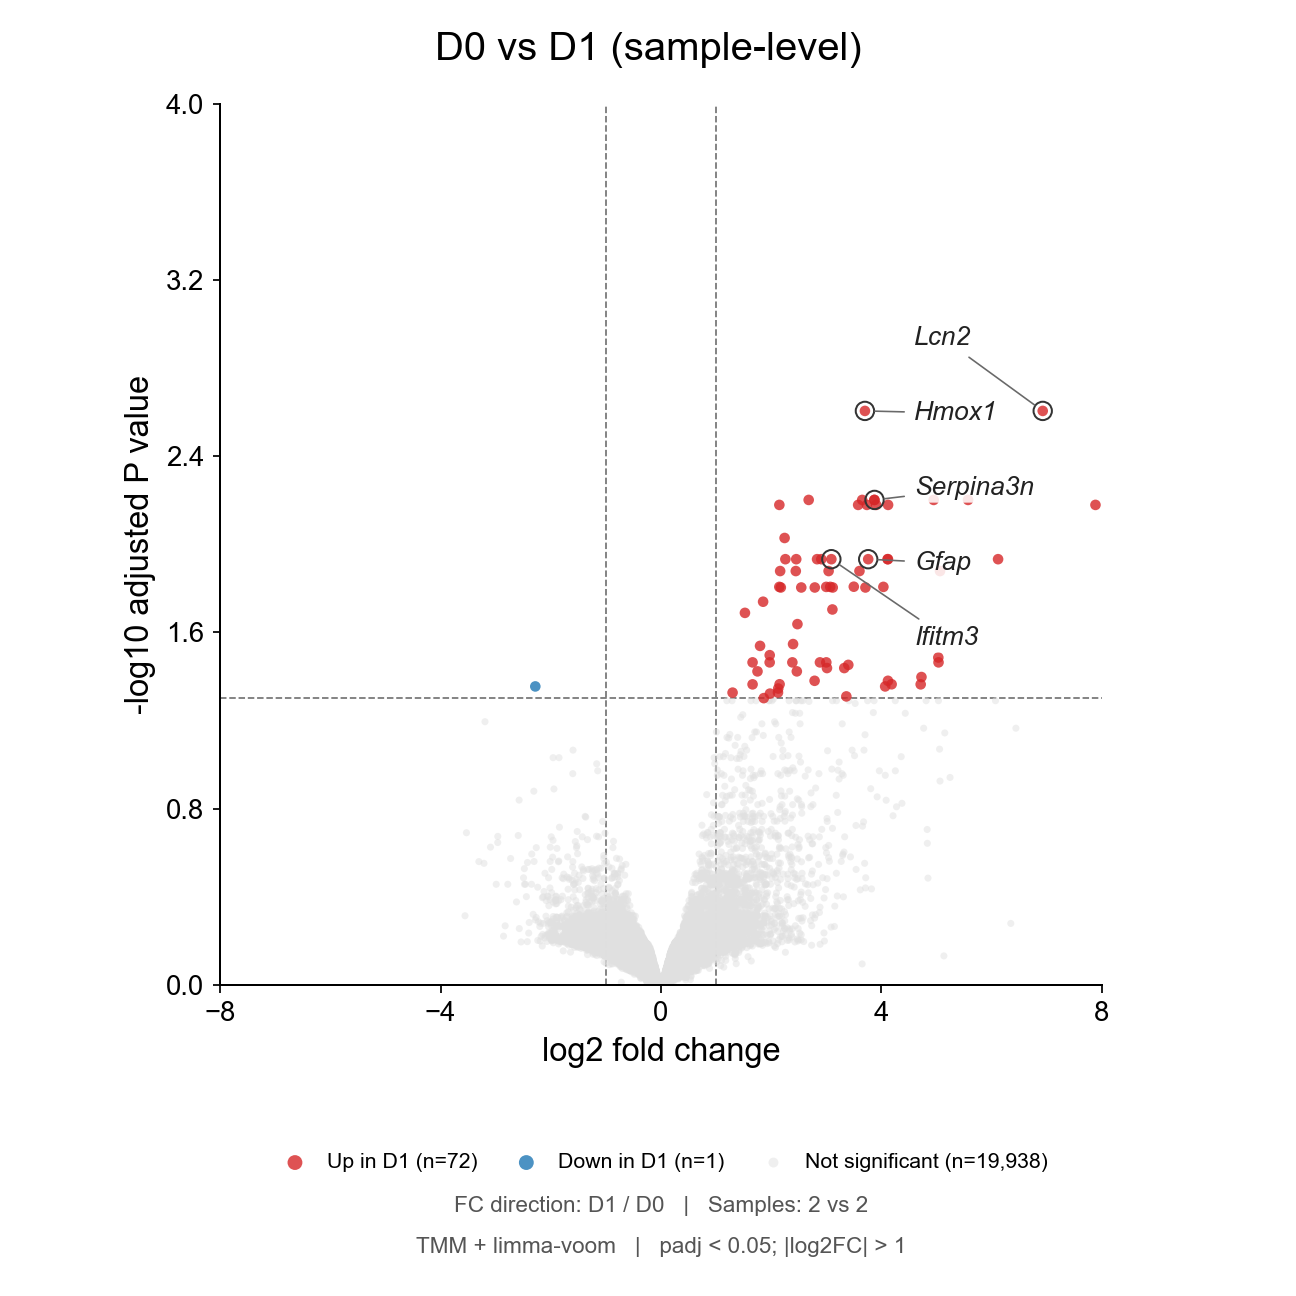

In [20]:
# 中文：图S9a：D0与D1的样本级差异。
# English: Figure S9a: sample-level D0 versus D1.
set_style(11)
run_plot(1, 'D0', 'D1')


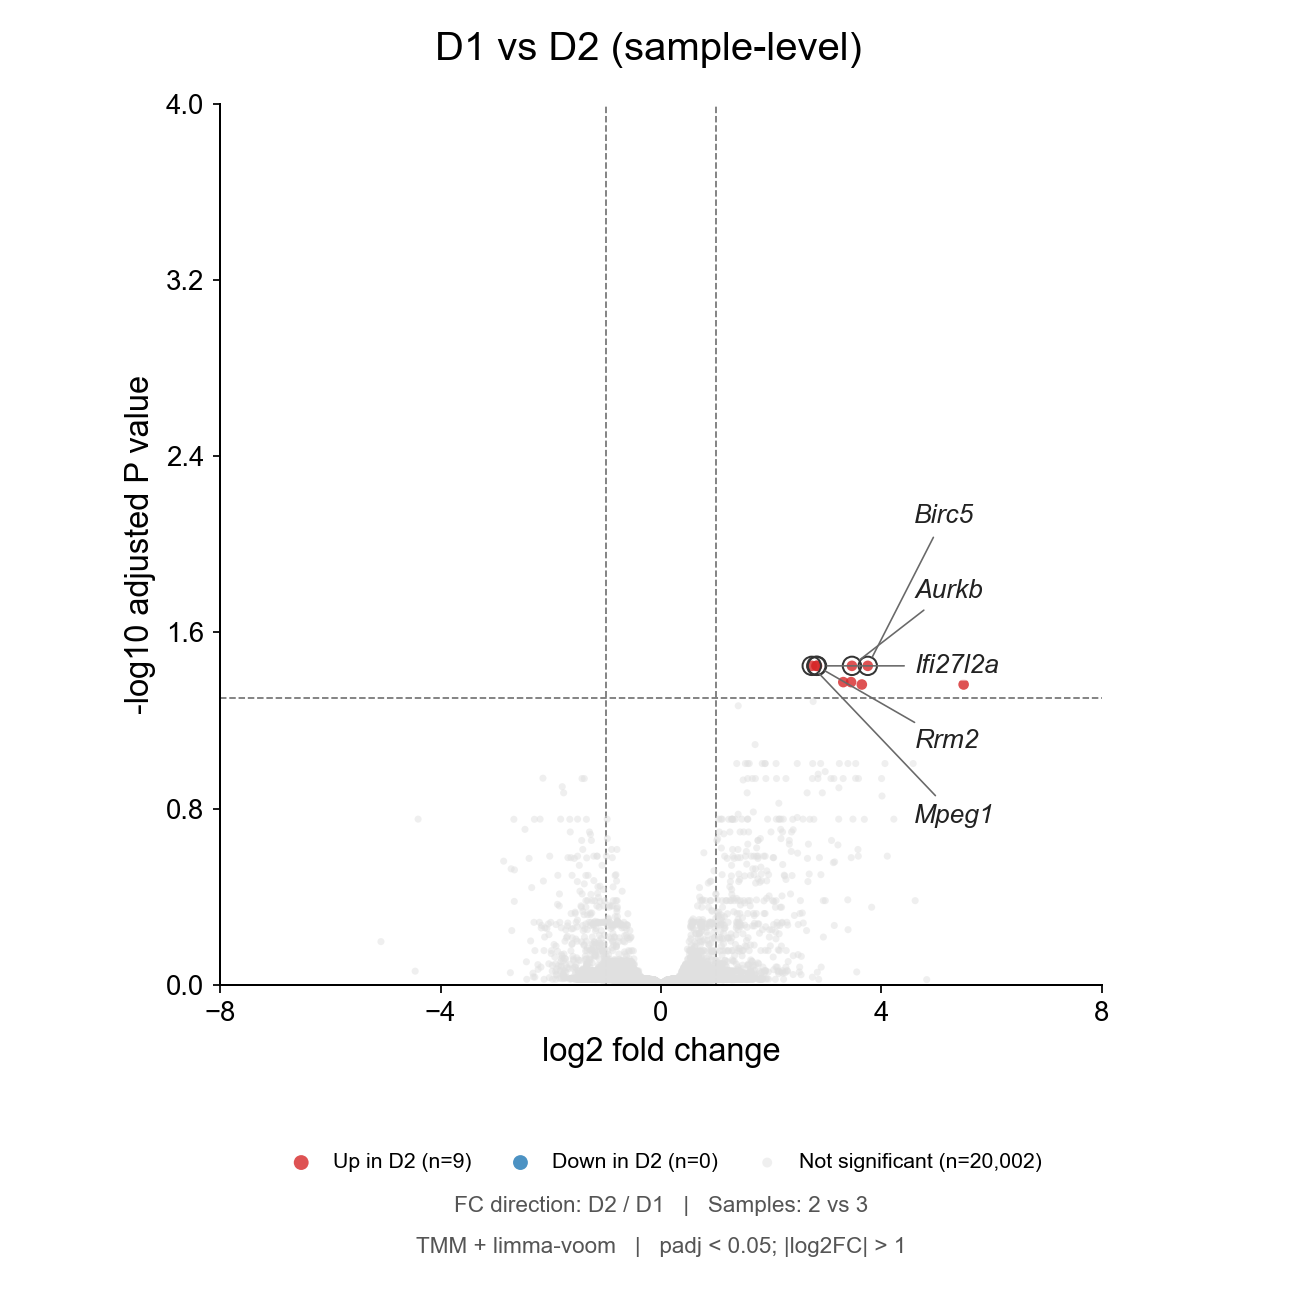

In [21]:
# 中文：图S9b：D1与D2的样本级差异。
# English: Figure S9b: sample-level D1 versus D2.
set_style(11)
run_plot(2, 'D1', 'D2')


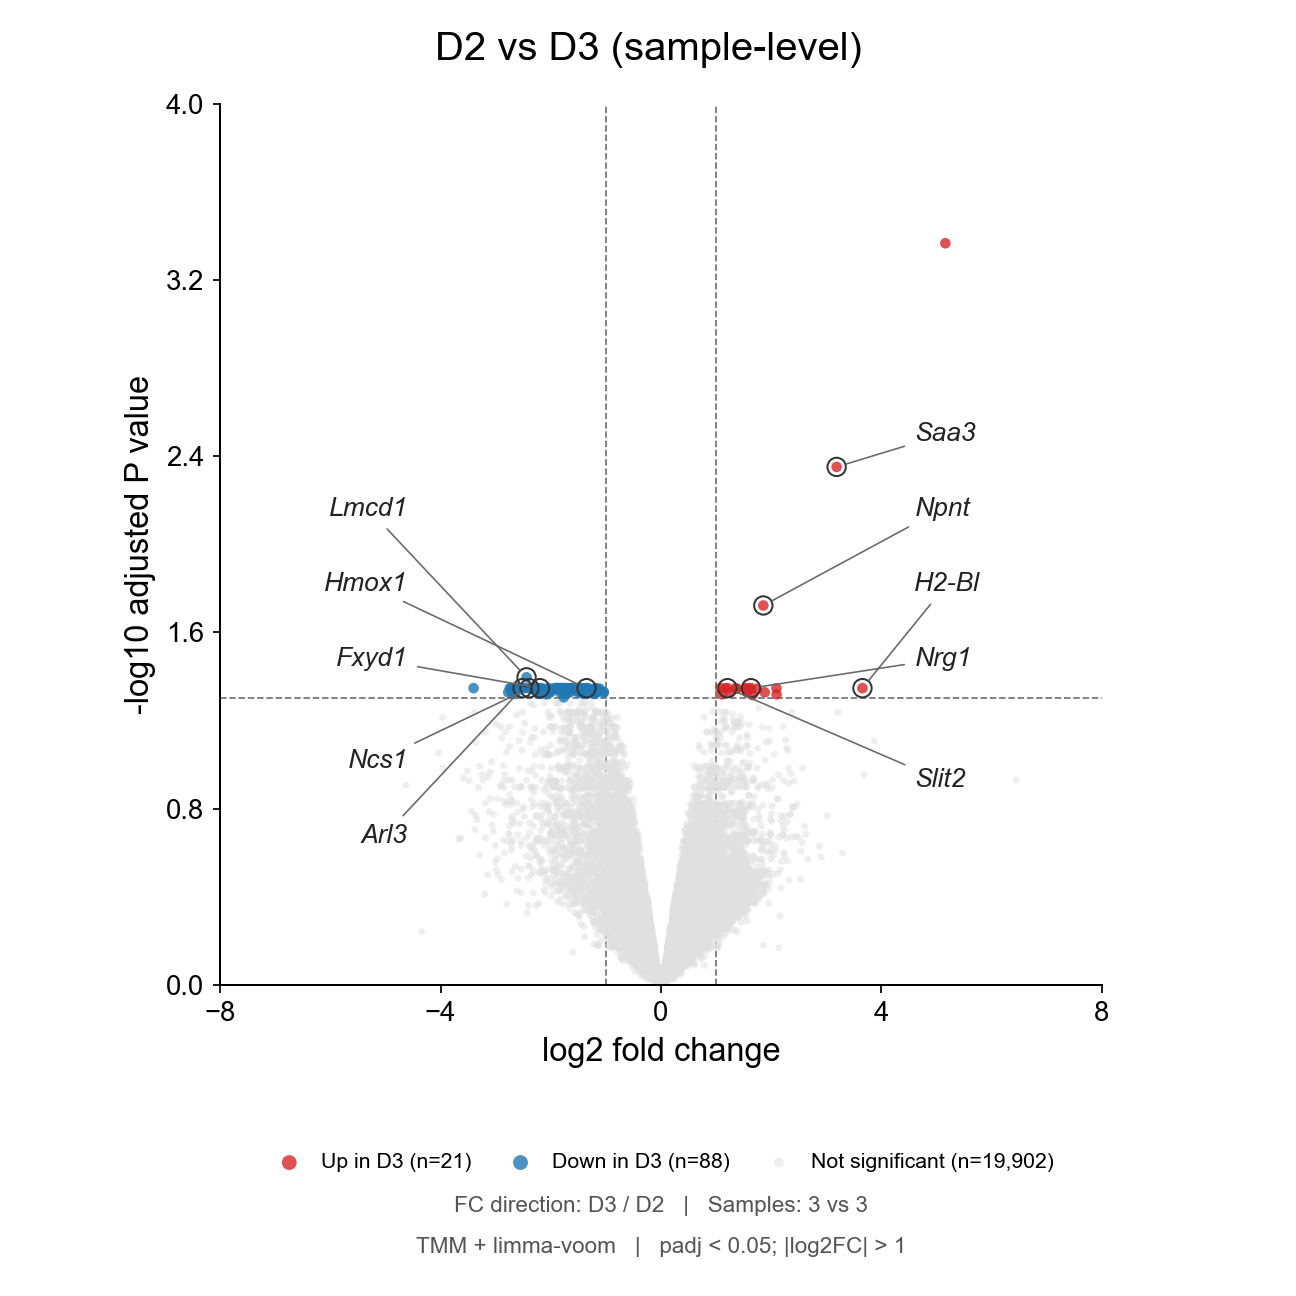

In [22]:
# 中文：图S9c：D2与D3的样本级差异。
# English: Figure S9c: sample-level D2 versus D3.
set_style(11)
run_plot(3, 'D2', 'D3')


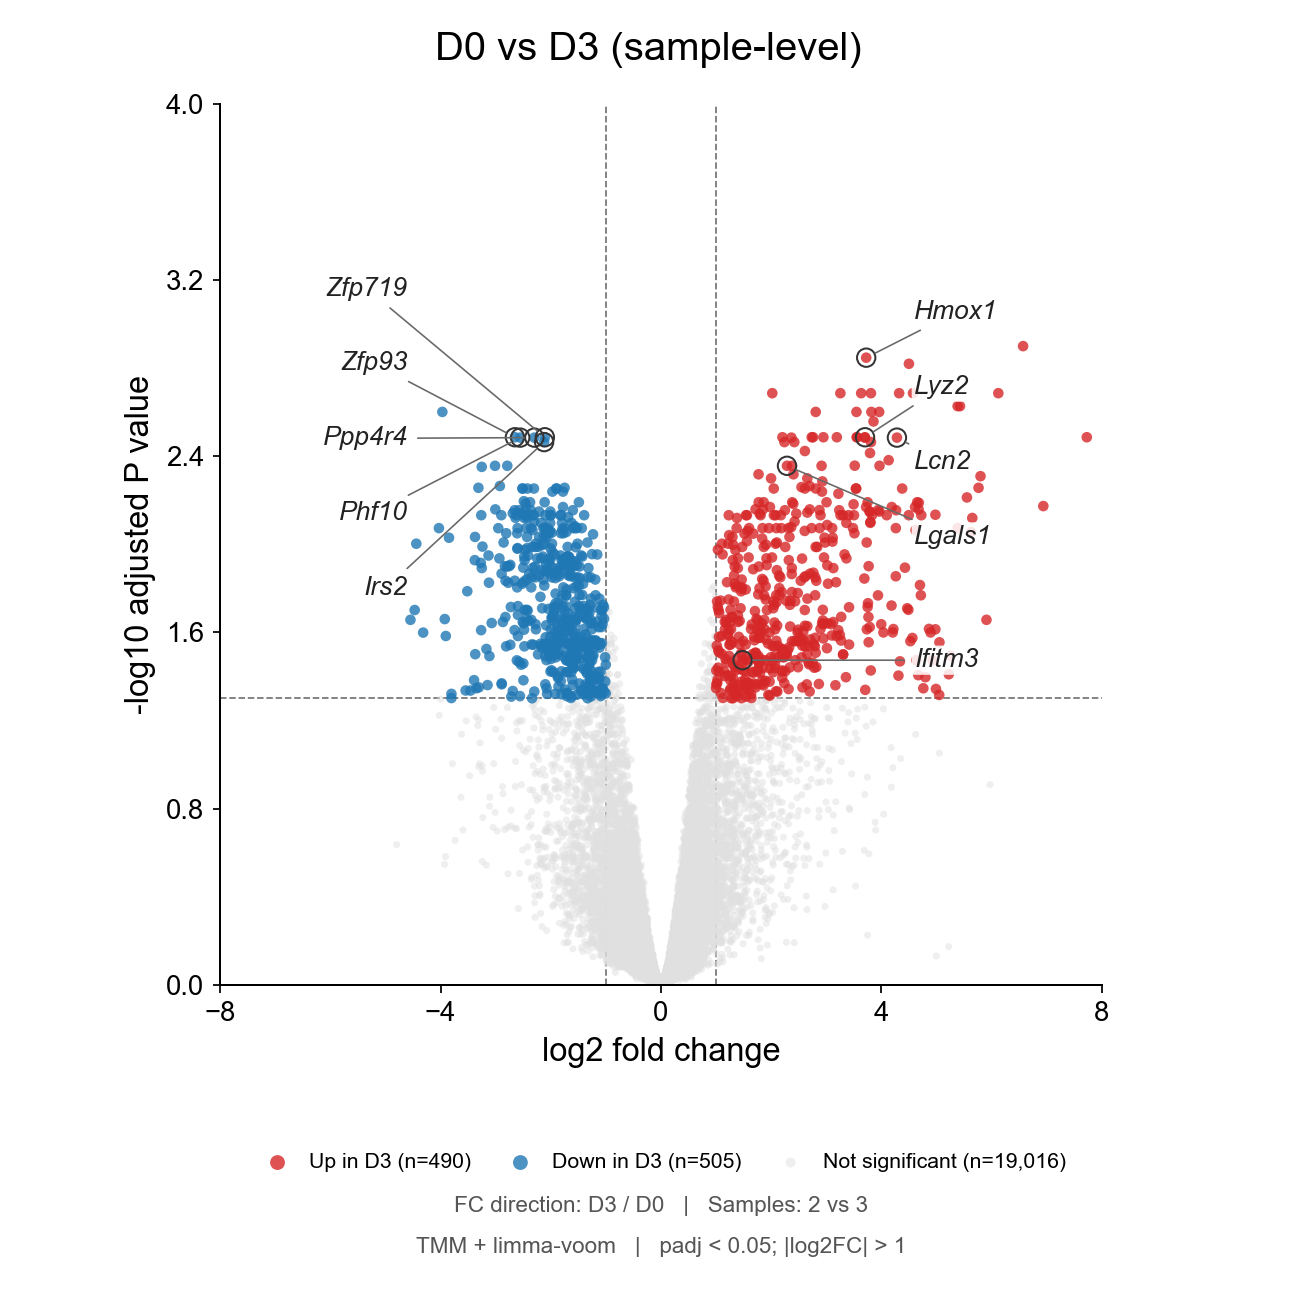

In [23]:
# 中文：图S9d：D0与D3的样本级差异。
# English: Figure S9d: sample-level D0 versus D3.
set_style(11)
run_plot(4, 'D0', 'D3')


## Figure S9e–f — GO Biological Process / GO生物过程

English: S9e uses the local GO BP analysis and S9f uses the g:Profiler analysis, provided as separate result sets in the data table. Eight terms are displayed per comparison. Adjusted P values use each analysis's full tested term family, with no correction restricted to displayed terms.

中文：S9e使用本地GO BP分析结果，S9f使用g:Profiler分析结果，两个结果集均包含在数据表中，每比较展示8条GO条目。校正P值使用各自完整受检条目集合。


In [24]:
# 中文：计算完整GO条目集合的统计并设置气泡图。
# English: Calculate statistics across the full GO term family and configure bubble plots.
go_tables = pd.read_csv(DATA / 'S9_GO_BP_statistics.csv.gz', float_precision='round_trip')
GO_VERSION = {'e': 'local', 'f': 'online'}
GO_COLOR_MAX = {'local': 37.59442565438192, 'online': 37.886750839743065}
for (version, category), frame in go_tables.groupby(['version', 'category'], sort=False):
    p = stats.hypergeom.sf(frame.gene_count - 1, frame.background_count, frame.term_background_count, frame.query_size)
    np.testing.assert_allclose(p, frame.raw_hypergeom_p, rtol=1e-9, atol=1e-15)
    np.testing.assert_allclose(multipletests(p, method='fdr_bh')[1], frame.adjusted_p, rtol=1e-9, atol=1e-14)
    np.testing.assert_allclose(frame.gene_ratio, frame.gene_count / frame.query_size, rtol=1e-12, atol=1e-15)
def draw_go(panel, earlier, later):
    set_style(11)
    version = GO_VERSION[panel]
    table = go_tables.loc[go_tables.version.eq(version) & go_tables.category.eq(f'{earlier}_vs_{later}_Up') & go_tables.display_order.notna()].sort_values('display_order')
    assert len(table) == 8
    cmap = LinearSegmentedColormap.from_list('template_blue_rose', ['#d8e3f0', '#7692C2', '#D37980'])
    norm = PowerNorm(gamma=.5, vmin=-np.log10(.05), vmax=GO_COLOR_MAX[version])
    fig = plt.figure(figsize=(8.8, 6.6))
    ax = fig.add_axes([.48, .16, .32, .70])
    yy = np.arange(len(table))
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#b2b7bd', linewidth=.65, alpha=.4)
    ax.scatter(table.gene_ratio, yy, s=50+22*np.sqrt(table.gene_count.to_numpy(float)),
               c=-np.log10(table.adjusted_p), cmap=cmap, norm=norm, edgecolor='#59677b', linewidth=.65)
    ax.set_yticks(yy, ['\n'.join(textwrap.wrap(t, width=37)) for t in table.term_name], fontsize=11)
    ax.set(ylim=(len(table)-.3, -.7), xlim=(0, .65), xlabel='Gene ratio', title=f'Upregulated in {later} (vs {earlier})')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis='y', length=0, pad=9)
    ax.spines[['top', 'right']].set_visible(False)
    cax = fig.add_axes([.86, .54, .022, .25])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    ticks = np.linspace(-np.log10(.05), GO_COLOR_MAX[version], 5)
    cb.set_ticks(ticks, labels=[f'{t:.1f}' for t in ticks])
    cb.set_label('-log10(adjusted P)', fontsize=10)
    handles = [Line2D([], [], marker='o', linestyle='', markersize=np.sqrt(50+22*np.sqrt(k)),
                      markerfacecolor='#7692C2', markeredgecolor='#59677b', markeredgewidth=.65, label=str(k)) for k in [1, 5, 25, 91]]
    fig.legend(handles=handles, title='Gene count', loc='center left', bbox_to_anchor=(.83, .30), frameon=False, fontsize=10)
    save_figure(fig, f'FigS9{panel}_GO_BP')


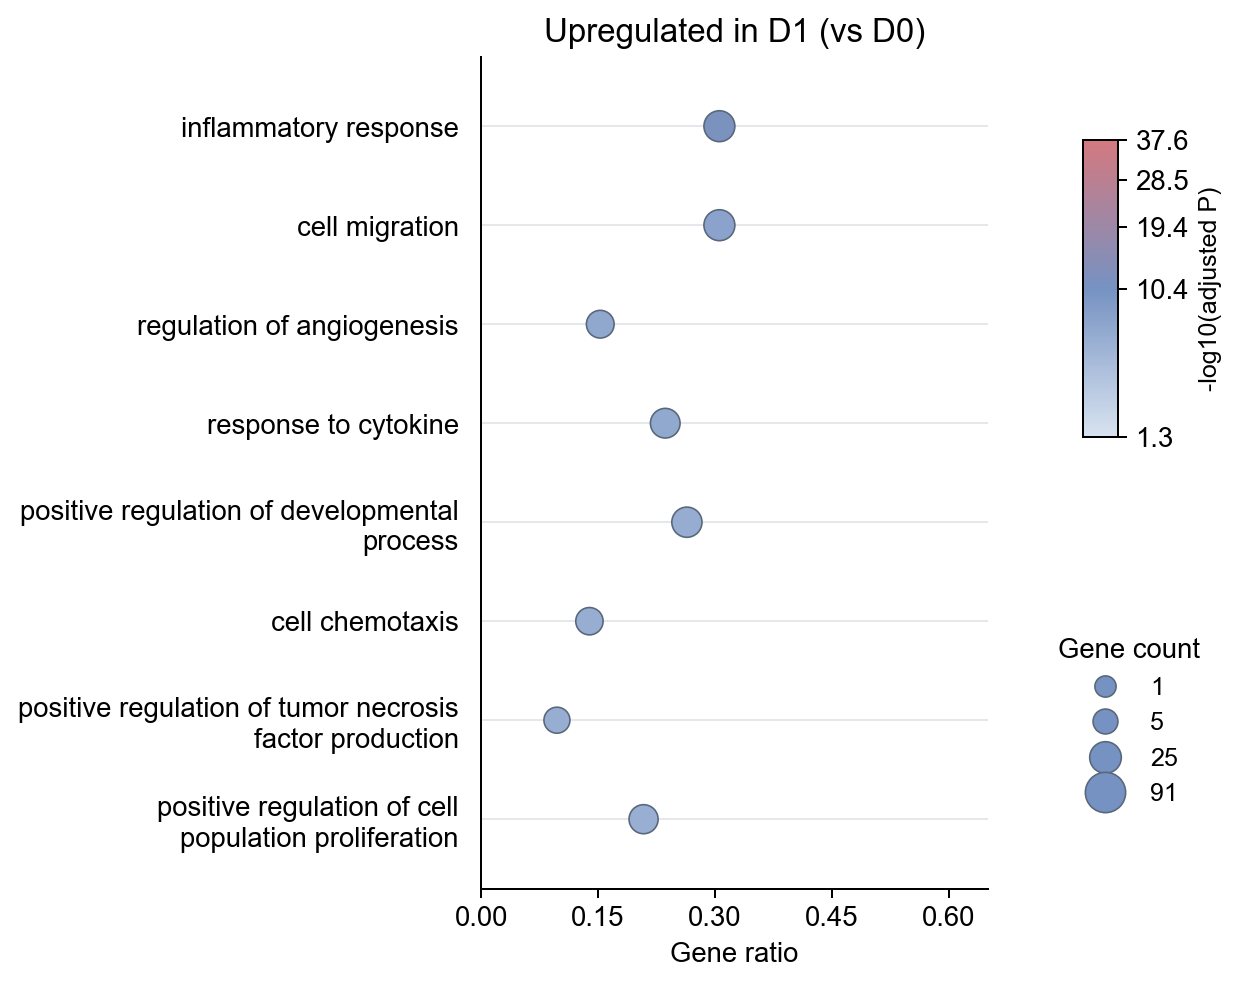

In [25]:
# 中文：图S9e：D1相对D0上调基因的GO富集。
# English: Figure S9e: GO enrichment of genes upregulated in D1 versus D0.
draw_go('e', 'D0', 'D1')


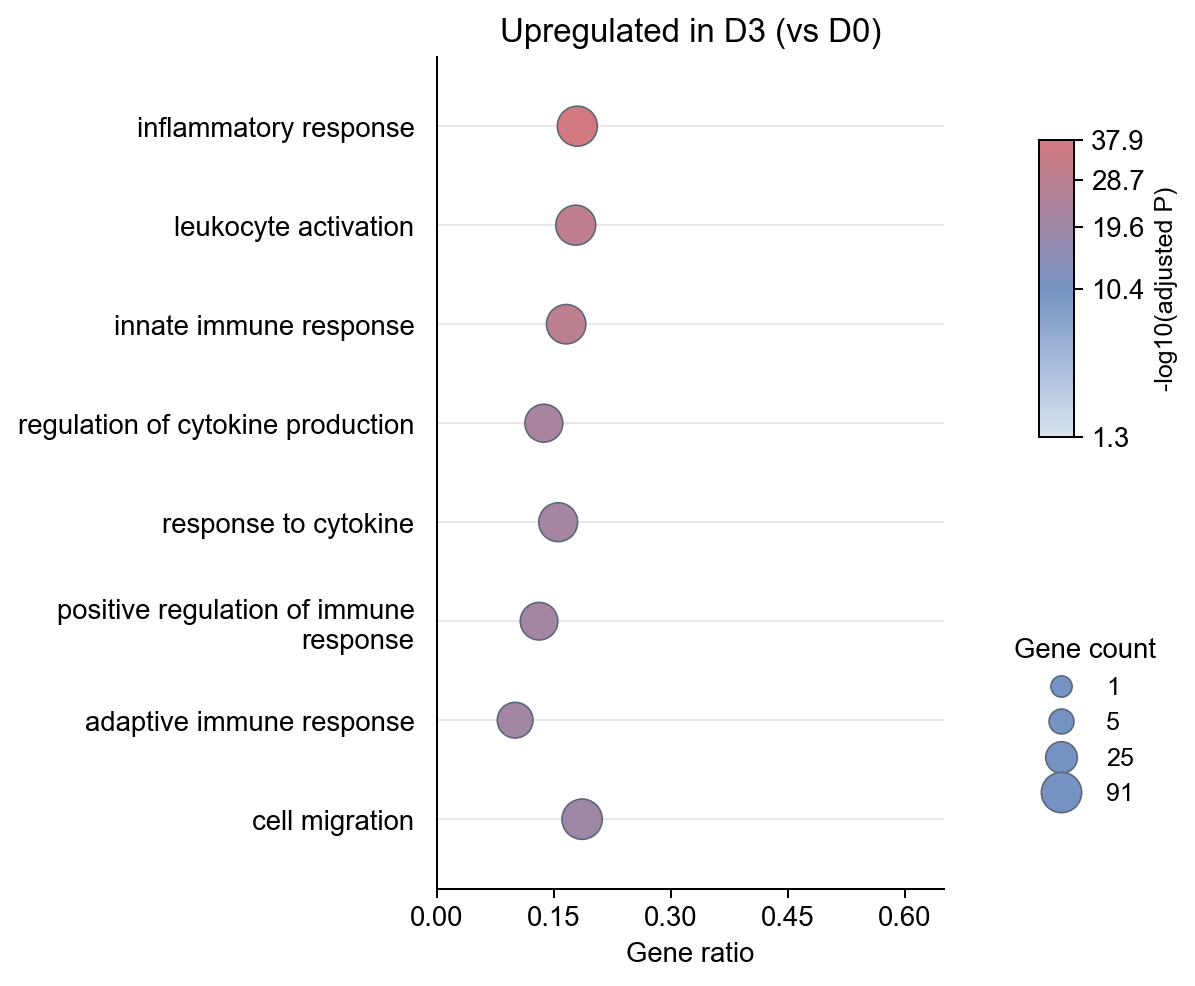

In [26]:
# 中文：图S9f：D3相对D0上调基因的GO富集。
# English: Figure S9f: GO enrichment of genes upregulated in D3 versus D0.
draw_go('f', 'D0', 'D3')


## Figure S10c — Sample cluster composition / 样本簇组成

English: Each bar shows cluster fractions among all retained spots in one sample. The S10a UMAP and S10b spatial maps are included in the combined views above.

中文：每个柱展示一个样本全部保留spot的簇比例。S10a的UMAP和S10b的空间图已合并在上方总览中。


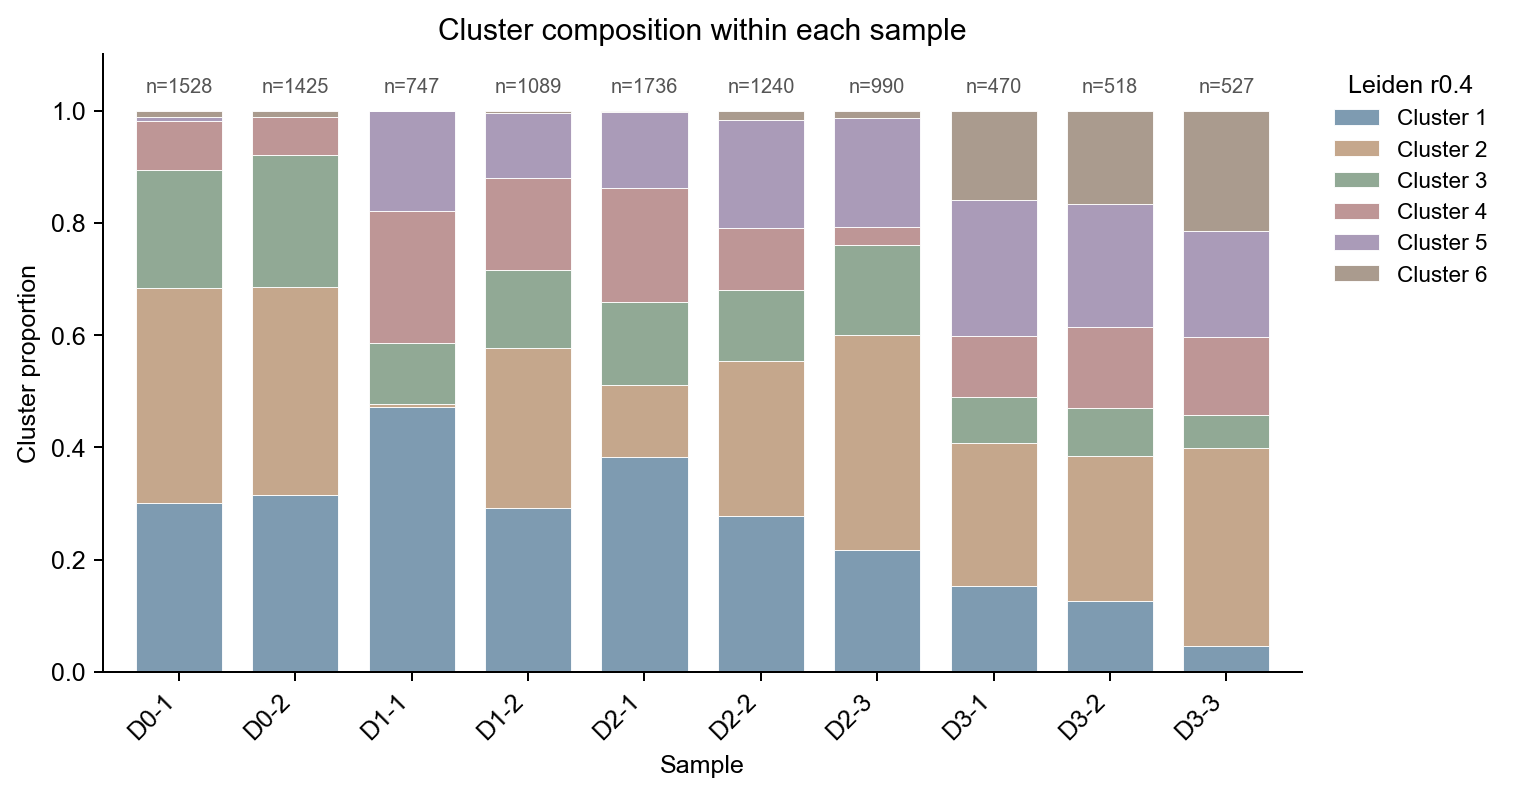

In [27]:
# 中文：图S10c：各样本簇比例，每个柱的分母为该样本所有保留spot。
# English: Figure S10c: within-sample cluster fractions, using all retained spots as the denominator.
set_style()
fig, ax = plt.subplots(figsize=(9, 4.9))
fig.subplots_adjust(left=.09, right=.83, bottom=.20, top=.90)
x = np.arange(len(SAMPLES))
bottom = np.zeros(len(SAMPLES))
for cluster in CLUSTERS:
    values = sample_proportions[cluster].to_numpy()
    ax.bar(x, values, bottom=bottom, width=.74, color=MUTED_PALETTE[CLUSTERS.index(cluster)],
           edgecolor="white", linewidth=.35, label=cluster)
    bottom += values
for pos, n in zip(x, counts.sum(axis=1)):
    ax.text(pos, 1.025, f"n={n}", ha="center", va="bottom", fontsize=8, color="#555555")
ax.set_xticks(x, [s[2:] for s in SAMPLES], rotation=45, ha="right")
ax.set_yticks(np.arange(0, 1.01, .2))
ax.set(xlabel="Sample", ylabel="Cluster proportion", ylim=(0, 1.10),
       xlim=(-.65, len(SAMPLES) - .35), title="Cluster composition within each sample")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Leiden r0.4", frameon=False, loc="upper left",
          bbox_to_anchor=(1.01, 1), fontsize=9, title_fontsize=10)
save_figure(fig, "FigS10c_cluster_proportions")


## Software versions / 软件版本

English: Package versions for the current notebook session.

中文：当前notebook会话使用的软件包版本。


In [28]:
# 中文：显示本次分析使用的软件包版本。
# English: Display package versions used in this analysis.
from importlib.metadata import version
assert len(FIGURE_OUTPUTS) == 16 and len(set(FIGURE_OUTPUTS)) == 16
assert sha256(INPUT_H5AD) == INPUT_HASH
assert displayed_samples == SAMPLES
np.testing.assert_allclose(sample_proportions.sum(axis=1), 1., atol=1e-12)
packages = ['anndata', 'scanpy', 'numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn', 'statsmodels']
display(pd.DataFrame({'Package': packages, 'Version': [version(p) for p in packages]}))


,Package,Version
0,anndata,0.11.4
1,scanpy,1.11.5
2,numpy,2.2.6
3,pandas,2.3.3
4,scipy,1.15.3
5,matplotlib,3.10.8
6,scikit-learn,1.7.2
7,statsmodels,0.14.6
